# LuminaTech Lighting: Sales Performance Analysis

Group project for BUSA8000 Techniques in Business Analytics, Macquarie University (Session 2, 2025). Team of five.

The raw sales data (`2023.csv`, `2024.csv`) was supplied for coursework and is not included in this repository.

# Answer to Section 1: Clean the dataset  (in this section, insert as many cells as needed)

## 1.1 Load and inspect the datasets

In [1]:
#Load necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print('Complete!')

Complete!


In [2]:
#Load each dataset separately for inspection
df_2023 = pd.read_csv("2023.csv",
                      dtype=str,
                      low_memory=False,
                      keep_default_na=True,
                      encoding="ISO-8859-1")

df_2024 = pd.read_csv("2024.csv",
                      dtype=str,
                      low_memory=False,
                      keep_default_na=True,
                      encoding="ISO-8859-1")


In [3]:
#Inspect the number of columns and rows of the 2 datasets
print(f'DF 2023 shape:{df_2023.shape}')
print(f'DF 2024 shape:{df_2024.shape}')

DF 2023 shape:(903702, 38)
DF 2024 shape:(884538, 39)


The dataframes are not equal in shape. There is an extra column in 2024 and 2023 has more rows.
Based on the visual inspection below (using df.head), the extra column in 2024 is customer_order_number.1. This will be further investigated to see its relevance in the dataset.

In [4]:
#Inspect the 2023 dataset - transpose the rows and columns to make the data easier to view
df_2023.head().T

,0,1,2,3,4
ï»¿accounting_date,20230523,NaN,NaN,NaN,NaN
fiscal_year,2023,NaN,NaN,NaN,NaN
fiscal_month,11,NaN,NaN,NaN,NaN
company_code,101,NaN,NaN,NaN,NaN
customer_code,598961420,NaN,NaN,NaN,NaN
customer_district_code,NaN,NaN,NaN,NaN,NaN
item_code,NaN,NaN,NaN,NaN,NaN
business_area_code,LMP,NaN,NaN,NaN,NaN
item_group_code,LMP01008,NaN,NaN,NaN,NaN
item_class_code,LMP01,NaN,NaN,NaN,NaN


In [5]:
#Inspect the 2024 dataset - transpose the rows and columns to make the data easier to view
df_2024.head().T

,0,1,2,3,4
accounting_date,NaN,NaN,20240611,20240111,20240321
fiscal_year,2024,NaN,2024,2024,NaN
fiscal_month,7,11,NaN,7,9
company_code,NaN,205,205,205,205
customer_code,NaN,NaN,584629402,0,942300030
customer_district_code,NaN,200,200,200,400
item_code,na,10311,10350,NaN,10364
business_area_code,COM,COM,OTH,OTH,COM
item_group_code,COM90001,COM90001,999,999,COM03002
item_class_code,COM90,COM90,14001,14001,COM03


In [6]:
#check if customer_order_number and customer_order_number.1 are duplicates
are_duplicates = df_2024['customer_order_number'].equals(df_2024['customer_order_number.1'])
print(f"Are the columns identical? {are_duplicates}")

Are the columns identical? True


Based on this check, the column "customer_order_number.1" is a duplicate. This column will be dropped in the next subsection to avoid redundancy.

In [7]:
#Inspect the column, observation count, and data types
print('2023 Info:')
print(df_2023.info())
print('2024 Info:')
print(df_2024.info())

2023 Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 903702 entries, 0 to 903701
Data columns (total 38 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   ï»¿accounting_date        903694 non-null  object
 1   fiscal_year               903694 non-null  object
 2   fiscal_month              903694 non-null  object
 3   company_code              903694 non-null  object
 4   customer_code             860108 non-null  object
 5   customer_district_code    903684 non-null  object
 6   item_code                 903691 non-null  object
 7   business_area_code        903694 non-null  object
 8   item_group_code           903694 non-null  object
 9   item_class_code           903694 non-null  object
 10  item_type                 903693 non-null  object
 11  bonus_group_code          903693 non-null  object
 12  environment_group_code    903693 non-null  object
 13  technology_group_code     903693 non-null  objec

In both datasets, the columns item_source_class and dss_update_time are empty. Both columns will be dropped in the next subsection.

In [8]:
# Calculate missing values for initial inspection
missing_2023 = df_2023.isnull().sum()
missing_2024 = df_2024.isnull().sum()

# Combine the missing values into one dataframe for better viewing
missing = pd.DataFrame({
    '2023_Missing': missing_2023,
    '2024_Missing': missing_2024
}).reset_index()
missing.columns = ["Feature", "2023_Missing", "2024_Missing"]

missing_filtered = missing[(missing["2023_Missing"] > 0) | (missing["2024_Missing"] > 0)]

# Display features with missing values
print("\nFeatures with missing values:")
print(missing_filtered)


Features with missing values:
                     Feature  2023_Missing  2024_Missing
0             abc_class_code           9.0          31.0
1           abc_class_volume           9.0          31.0
2            accounting_date           NaN          11.0
3           bonus_group_code           9.0          31.0
4         business_area_code           8.0          36.0
5     business_chain_l1_code           9.0          32.0
6     business_chain_l1_name           9.0          36.0
7      commission_group_code           9.0          32.0
8               company_code           8.0          30.0
9        contact_method_code           9.0          34.0
10                  currency           9.0          20.0
11             customer_code       43594.0       60139.0
12    customer_district_code          18.0          33.0
13     customer_order_number           9.0          20.0
14   customer_order_number.1           NaN          20.0
15           dss_update_time      903702.0      884538.0


Observations:
- As identified above, the columns dss_update_time, item_source_class are empty and should be dropped.
- As previously identified, customer_order_number.1 is a duplicate column and should also be dropped.
- The column "ï»¿accounting_date" in 2023 have special characters and should be renamed to align with the same column in 2024.
- The column customer_code has relatively large null values and will be investigated in the following subsections when the datasets are merged.
- The 2023 dataset has more or less 8 null values in all other columns while there are about 30 null values in all other columns in 2024.

## 1.2 Format each dataset separately
The datasets are formatted separately to ensure they have the same columns and datatypes before merging.

In [9]:
#Drop the empty columns and the duplicate column identified above
drop_cols = ['item_source_class', 'dss_update_time', 'customer_order_number.1']

df_2023 = df_2023.drop(columns=drop_cols, errors='ignore')
df_2024 = df_2024.drop(columns=drop_cols, errors='ignore')

In [10]:
# Rename the accounting column in 2023 dataframe
df_2023 = df_2023.rename(columns={'ï»¿accounting_date': 'accounting_date'})

In [11]:
# Format the columns to reflect their datatypes

#1. Time-related columns
time_cols = ['fiscal_year', 'fiscal_month']
for c in [df_2023, df_2024]:
  for col in time_cols:
    c[col] = (
        c[col].astype(str).str.extract(r'(\d+)')[0].astype('Int64')
    )

#check to see if formatting has been done correctly
print(f'2023 time cols \n {df_2023[time_cols].head(5)}')
print(f'2024 time cols \n {df_2024[time_cols].head(5)}')

2023 time cols 
    fiscal_year  fiscal_month
0         2023            11
1         <NA>          <NA>
2         <NA>          <NA>
3         <NA>          <NA>
4         <NA>          <NA>
2024 time cols 
    fiscal_year  fiscal_month
0         2024             7
1         <NA>            11
2         2024          <NA>
3         2024             7
4         <NA>             9


In [12]:
#2. format numeric columns
numeric_cols = ['value_sales', 'value_cost',
    'value_quantity', 'value_price_adjustment',
    'line_number'
]

for col in numeric_cols:
    df_2023[col] = pd.to_numeric(df_2023[col], errors='coerce')

for col in numeric_cols:
    df_2024[col] = pd.to_numeric(df_2024[col], errors='coerce')

#check to see if formatting has been done correctly
print(f'2023 numeric cols \n {df_2023[numeric_cols].head(5)}')
print(f'2024 numeric cols \n {df_2024[numeric_cols].head(5)}')

2023 numeric cols 
    value_sales  value_cost  value_quantity  value_price_adjustment  \
0         20.1         NaN             6.0                     0.0   
1          NaN         NaN             NaN                     NaN   
2          NaN         NaN             NaN                     NaN   
3          NaN         NaN             NaN                     NaN   
4          NaN         NaN             NaN                     NaN   

   line_number  
0          1.0  
1          NaN  
2          NaN  
3          NaN  
4          NaN  
2024 numeric cols 
    value_sales  value_cost  value_quantity  value_price_adjustment  \
0        -2.23      -1.270            -1.0                     0.0   
1         2.48         NaN             1.0                     0.0   
2        53.40      22.970             2.0                     NaN   
3        24.90      11.485             NaN                     0.0   
4        45.00      28.140             6.0                     0.0   

   line_number  

In [13]:
#3. convert date columns to datetime
dt_cols = [
    'accounting_date', 'invoice_date', 'order_date'
]

for col in dt_cols:
    df_2023[col] = pd.to_datetime(df_2023[col], errors='coerce')
    df_2024[col] = pd.to_datetime(df_2024[col], errors='coerce')

#check to see if formatting has been done correctly
print(f'2023 datetime cols \n {df_2023[dt_cols].head(5)}')
print(f'2024 datetime cols \n {df_2024[dt_cols].head(5)}')

2023 datetime cols 
   accounting_date invoice_date order_date
0      2023-05-23   2023-05-23 2023-05-23
1             NaT          NaT        NaT
2             NaT          NaT        NaT
3             NaT          NaT        NaT
4             NaT          NaT        NaT
2024 datetime cols 
   accounting_date invoice_date order_date
0             NaT   2024-01-25 2024-01-25
1             NaT   2024-05-13 2024-05-10
2      2024-06-11   2024-06-11 2024-06-11
3      2024-01-11   2024-01-11 2024-01-11
4      2024-03-21   2024-03-21 2024-03-20


In [14]:
#4. format categorical columns
categorical_cols = [
    'company_code', 'customer_code', 'customer_district_code', 'item_code',
    'business_area_code', 'item_group_code', 'item_class_code', 'item_type',
    'bonus_group_code', 'environment_group_code', 'technology_group_code',
    'commission_group_code', 'reporting_classification', 'light_source',
    'warehouse_code', 'abc_class_code', 'business_chain_l1_code',
    'business_chain_l1_name', 'contact_method_code', 'salesperson_code', 'order_type_code',
    'currency', 'abc_class_volume', 'market_segment', 'invoice_number', 'customer_order_number'
]

na_like = ["", " ", "  ", "   ",  "na", "n/a", "na.", "nan", "null", "unk", "unknown", "-", "Na", "NA", "0", "Ukn", "Unk", ""]

for col in categorical_cols:
    df_2023[col] = df_2023[col].astype(str).str.strip()
    df_2023[col] = df_2023[col].astype(object)
    df_2023[col] = df_2023[col].replace(na_like, np.nan)

for col in categorical_cols:
    df_2024[col] = df_2024[col].astype(str).str.strip()
    df_2024[col] = df_2024[col].astype(object)
    df_2024[col] = df_2024[col].replace(na_like, np.nan)

#check to see if formatting has been done correctly
print(f'2023 categorical cols \n {df_2023[categorical_cols].head(5)}')
print(f'2024 categorical cols \n {df_2024[categorical_cols].head(5)}')

2023 categorical cols 
   company_code customer_code customer_district_code item_code  \
0          101     598961420                    NaN       NaN   
1          NaN           NaN                    NaN       NaN   
2          NaN           NaN                    NaN       NaN   
3          NaN           NaN                    NaN       NaN   
4          NaN           NaN                    NaN       NaN   

  business_area_code item_group_code item_class_code item_type  \
0                LMP        LMP01008           LMP01         5   
1                NaN             NaN             NaN       NaN   
2                NaN             NaN             NaN       NaN   
3                NaN             NaN             NaN       NaN   
4                NaN             NaN             NaN       NaN   

  bonus_group_code environment_group_code  ... business_chain_l1_code  \
0            Trade                      S  ...                    MED   
1              NaN                    NaN 

In [15]:
# revisit missing values after formatting the datatypes
missing_2023 = df_2023.isnull().sum()
missing_2024 = df_2024.isnull().sum()

# Combine missing values into 1 dataframe
missing = pd.DataFrame({
    '2023_Missing': missing_2023,
    '2024_Missing': missing_2024
}).reset_index()
missing.columns = ["Feature", "2023_Missing", "2024_Missing"]

missing_filtered = missing[(missing["2023_Missing"] > 0) | (missing["2024_Missing"] > 0)]

# Display features with missing values
print("\nFeatures with missing values:")
print(missing_filtered)


Features with missing values:
                     Feature  2023_Missing  2024_Missing
0            accounting_date          4214            12
1                fiscal_year             8            31
2               fiscal_month             8            27
3               company_code             8            31
4              customer_code         43594         60152
5     customer_district_code            22            34
6                  item_code            11            43
7         business_area_code             8            36
8            item_group_code             8            34
9            item_class_code             8            34
10                 item_type             9            33
11          bonus_group_code             9            31
12    environment_group_code            60            57
13     technology_group_code        107951         84158
14     commission_group_code             9            32
15  reporting_classification             9            37


Observations:
After fixing the data types, more null values have been observed especially in the following columns: technology group code, warehouse code, and contact method code. The contact method code column is about 95% missing, so this column is dropped.

In [16]:
#Drop contact method code
df_2023 = df_2023.drop(columns='contact_method_code', errors='ignore')
df_2024 = df_2024.drop(columns='contact_method_code', errors='ignore')

print(f"DF 2023 shape: {df_2023.shape}")
print(f"DF 2024 shape: {df_2024.shape}")

DF 2023 shape: (903702, 35)
DF 2024 shape: (884538, 35)


## 1.3 Merge datasets and apply further data cleaning

In [17]:
#Merge the two datasets
df_2023["year"] = 2023
df_2024["year"] = 2024
df = pd.concat([df_2023, df_2024], ignore_index=True)

In [18]:
#Drop rows with more than 50% null values
threshold = df.shape[1] * 0.5  # rows must have ≥ 50% non-nulls

print(f"Before: {len(df)} rows")
df = df.dropna(thresh=threshold)
print(f"After:  {len(df)} rows")

# check how many rows have multiple nulls after dropping
null_counts = df.isna().sum(axis=1)
for i in range(1, int(df.shape[1] * 0.5)):
    print(f"Rows with ≥ {i} nulls: {(null_counts >= i).sum()}")


Before: 1788240 rows
After:  1788204 rows
Rows with ≥ 1 nulls: 354247
Rows with ≥ 2 nulls: 122585
Rows with ≥ 3 nulls: 3061
Rows with ≥ 4 nulls: 565
Rows with ≥ 5 nulls: 72
Rows with ≥ 6 nulls: 9
Rows with ≥ 7 nulls: 8
Rows with ≥ 8 nulls: 8
Rows with ≥ 9 nulls: 6
Rows with ≥ 10 nulls: 5
Rows with ≥ 11 nulls: 4
Rows with ≥ 12 nulls: 3
Rows with ≥ 13 nulls: 3
Rows with ≥ 14 nulls: 3
Rows with ≥ 15 nulls: 3
Rows with ≥ 16 nulls: 3
Rows with ≥ 17 nulls: 2


In [19]:
#Drop duplicate rows

duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed. New shape:", df.shape)

Number of duplicate rows: 7107
Duplicates removed. New shape: (1781097, 36)


In [20]:
# Drop order type codes that should not be used per instruction in the metadata
drop_value = ['EDS', 'OBS', 'PPD', 'PM0', 'PGS', 'SPL', 'ZOP', 'ZC2', '5TN', 'PPO', 'ZD3', 'CSO']
df = df[~df['order_type_code'].isin(drop_value)]

print("invalid order types removed. New shape:", df.shape)

invalid order types removed. New shape: (1768390, 36)


In [21]:
# Inspect unique values per column to further investigate anomalies

for col in df.columns:
    unique_vals = df[col].unique()
    print(f"\n{col}: {len(unique_vals)} unique values")

    # Add date range for datetime columns
    if df[col].dtype == 'datetime64[ns]':
        print(f"Range: {df[col].min()} to {df[col].max()}")

    print(f"Sample: {unique_vals[:30]}")


accounting_date: 542 unique values
Range: 2023-01-02 00:00:00 to 2024-12-31 00:00:00
Sample: <DatetimeArray>
['2023-05-23 00:00:00', '2023-02-02 00:00:00', '2023-03-01 00:00:00',
 '2023-05-03 00:00:00', '2023-03-20 00:00:00', '2023-01-18 00:00:00',
 '2023-06-05 00:00:00', '2023-03-07 00:00:00', '2023-04-27 00:00:00',
 '2023-05-04 00:00:00', '2023-01-31 00:00:00', '2023-04-24 00:00:00',
 '2023-02-24 00:00:00', '2023-04-23 00:00:00', '2023-05-25 00:00:00',
 '2023-02-03 00:00:00', '2023-05-02 00:00:00', '2023-06-04 00:00:00',
 '2023-04-04 00:00:00', '2023-04-20 00:00:00', '2023-04-19 00:00:00',
 '2023-03-19 00:00:00', '2023-01-24 00:00:00', '2023-05-10 00:00:00',
 '2023-06-08 00:00:00', '2023-02-10 00:00:00', '2023-06-15 00:00:00',
 '2023-03-26 00:00:00', '2023-03-13 00:00:00', '2023-03-28 00:00:00']
Length: 30, dtype: datetime64[ns]

fiscal_year: 4 unique values
Sample: <IntegerArray>
[2023, 2024, <NA>, 2025]
Length: 4, dtype: Int64

fiscal_month: 14 unique values
Sample: <IntegerArray>

In [22]:
#Inspect the frequency per value in each column
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: accounting_date
accounting_date
2024-04-30    8099
2023-02-02    5769
2023-04-03    5658
2024-05-28    5629
2023-06-05    5593
              ... 
2023-04-22       2
2024-08-31       2
2023-06-30       1
2024-03-29       1
2024-01-06       1
Name: count, Length: 542, dtype: int64

Column: fiscal_year
fiscal_year
2024    835467
2023    530443
2025    402472
<NA>         8
Name: count, dtype: Int64

Column: fiscal_month
fiscal_month
11      211234
12      173970
9       161690
10      159645
8       158935
1       153944
2       144726
7       137364
4       131990
3       127468
5       119401
6        88014
13           5
<NA>         4
Name: count, dtype: Int64

Column: company_code
company_code
205    1243786
101     313521
950     103244
220      83724
100      19946
140       3538
240        519
120         78
170         19
510          9
NaN          6
Name: count, dtype: int64

Column: customer_code
customer_code
NaN           103272
469500002      54866
1050400200     1

Observations:
- There are zero values in the sales and cost columns. These observations may not be meaningful business transactions.
- The currency column has the category "AUS" which is not a valid currency. This will be replaced with "AUD." Since there are multiple currencies in the dataset, we will create new columns for sales and cost to standardize the values into AUD to simplify and streamline our analysis. We will keep the original columns for other possible exploratory analysis. The conversions are based on these sources:
  https://www.ato.gov.au/tax-rates-and-codes/foreign-exchange-rates-annual-2024-financial-year <br>
  https://www.ato.gov.au/tax-rates-and-codes/foreign-exchange-rates-annual-2025-financial-year
- There are negative values in line number, value sales, value cost, and value quantity. These should be further investigated to see what they mean in this business context.
- There is only 1 market segment captured in this dataset which is commercial and industrial.

### 1.3.1 Handle unique values

In [23]:
#Handle zero values in sales and cost columns since these rows are not meaningful business transactions and do not add valuable insights to the analysis

#Check how many transactions have $0 sales, $0 cost, or both
zero_sales = np.isclose(df['value_sales'].fillna(np.inf), 0.0, atol=1e-9)
percentage_zero_sales = zero_sales.mean() * 100
print(f"Percentage of rows with value_sales = 0: {percentage_zero_sales:.2f}%")

zero_cost  = np.isclose(df['value_cost'].fillna(np.inf),  0.0, atol=1e-9)
percentage_zero_cost =  zero_cost.mean() * 100
print(f"Percentage of rows with value_cost = 0: {percentage_zero_cost:.2f}%")

both_zero  = zero_sales & zero_cost
percentage_both_zero =  both_zero.mean() * 100
print(f"Percentage of rows with both 0: {percentage_both_zero:.2f}%")

print("Before drop, rows with both zero:", both_zero.sum())
print("Df shape before drops:", df.shape)

Percentage of rows with value_sales = 0: 1.13%
Percentage of rows with value_cost = 0: 2.33%
Percentage of rows with both 0: 0.02%
Before drop, rows with both zero: 289
Df shape before drops: (1768390, 36)


In [24]:
#Remove the rows where either sales or cost is zero
df = df[~(zero_sales | zero_cost)]
print(f"Rows remaining: {len(df)}")
print(f"Rows with both 0s left: {(df['value_sales'] == 0).sum() and (df['value_cost'] == 0).sum()}")
print(df.shape)

Rows remaining: 1707569
Rows with both 0s left: 0
(1707569, 36)


In [25]:
#Chang Fiscal month >12 to 12
df.loc[df['fiscal_month'] > 12, 'fiscal_month'] = 12

In [26]:
#Change "AUS" to AUD
df['currency'] = df['currency'].replace('AUS', 'AUD')

print("\nAfter cleaning:")
print("Currency values:", df['currency'].unique())


After cleaning:
Currency values: ['AUD' 'USD' 'NZD' 'EUR' nan]


In [27]:
#Standardize the currency of value sales and value cost

# Define conversion rates to AUD
rates_2023 = {'USD': 0.6181, 'EUR': 1.0768, 'NZD': 0.6840} #based on https://www.ato.gov.au/tax-rates-and-codes/foreign-exchange-rates-annual-2024-financial-year
rates_2024 = {'USD': 0.5586, 'EUR': 1.0768, 'NZD': 0.6550} #based on https://www.ato.gov.au/tax-rates-and-codes/foreign-exchange-rates-annual-2025-financial-year

def convert_sales_to_aud(row):
    if row['currency'] in ['USD', 'EUR', 'NZD']:
        if row['year'] == 2023:
            return float(row['value_sales']) / rates_2023[row['currency']]
        elif row['year'] == 2024:
            return float(row['value_sales']) / rates_2024[row['currency']]
    return float(row['value_sales'])  # already AUD or unknown

# Apply conversion - create new column
df['value_sales_aud'] = df.apply(convert_sales_to_aud, axis=1)

# Apply conversion based on 'currency' and 'year' columns for value_cost
def convert_cost_to_aud(row):
    if row['currency'] in ['USD', 'EUR', 'NZD']:
        if row['year'] == 2023:
            return float(row['value_cost']) / rates_2023[row['currency']]
        elif row['year'] == 2024:
            return float(row['value_cost']) / rates_2024[row['currency']]
    return float(row['value_cost'])

# Apply conversion - create new column
df['value_cost_aud'] = df.apply(convert_cost_to_aud, axis=1)

# Keep original currency column for reference

### 1.3.2 Handle missing values

In [28]:
#reinspect missing values
df.isna().sum()

,0
accounting_date,3820
fiscal_year,8
fiscal_month,4
company_code,6
customer_code,98722
customer_district_code,21
item_code,20
business_area_code,8
item_group_code,7
item_class_code,7


In [29]:
#Calculate missing percentages for the following columns
columns_to_check = [
    'accounting_date', 'customer_code', 'technology_group_code',
    'warehouse_code', 'invoice_date', 'order_date'
]

total_records = len(df)

for col in columns_to_check:
    missing_count = df[col].isna().sum()
    missing_pct = (missing_count / total_records) * 100
    print(f"{col}: {missing_pct:.2f}% missing")

accounting_date: 0.22% missing
customer_code: 5.78% missing
technology_group_code: 10.87% missing
warehouse_code: 9.68% missing
invoice_date: 0.22% missing
order_date: 0.21% missing


- The columns customer_code, technology_group, and warehouse_codes have the most missing values. These columns will be imputed with mode based on the following:
  - customer_code: customer_district_code and business_chain_code since customers are logically grouped by location and business relationships.
  - technology_group code: item_group_code since technology groups can be presumed to be consistent within product categories.
  - warehouse_code: customer_district_code and business_chain_code since warehouses serve specific geographic districts and business chains
- Missing datetime observations will be dropped given minimal loss in data and that it is difficult to impute meaningfully.
- Categorical columns with less than 1% missing will also be dropped given minimal loss in data and to avoid creating artificial patterns.
-  Numeric columns, particularly, value_sales, value_cost, value_quantity, and value_price_adjustment will be imputed with median values based on item_group_code and currency to maintain realistic pricing patterns and market differences.

In [30]:
#Handle customer_code, technology_group, and warehouse_codes
df['customer_code'] = df.groupby(['customer_district_code', 'business_chain_l1_code'])['customer_code'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan)
df['technology_group_code'] = df.groupby('item_group_code')['technology_group_code'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan)
df['warehouse_code'] = df.groupby(['customer_district_code', 'business_chain_l1_code'])['warehouse_code'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan)

In [31]:
# Check remaining null values
nan_counts = {
    'customer_code': df['customer_code'].isna().sum(),
    'technology_group_code': df['technology_group_code'].isna().sum(),
    'warehouse_code': df['warehouse_code'].isna().sum()
}

for var, count in nan_counts.items():
    print(f"{var}: {count} NaN values")

customer_code: 98451 NaN values
technology_group_code: 7697 NaN values
warehouse_code: 27 NaN values


In [32]:
# Drop the rows
df = df.dropna(subset=['customer_code', 'technology_group_code', 'warehouse_code'])

In [33]:
#Drop missing datetime values
datetime_cols = ['accounting_date', 'invoice_date', 'order_date']
df = df.dropna(subset=datetime_cols)

In [34]:
#Impute numeric columns with median by product group and currency
num_cols = ['value_sales', 'value_cost', 'value_quantity']
for col in num_cols:
    df[col] = df.groupby(['item_group_code', 'currency'])[col].transform(
        lambda x: x.fillna(x.median())
    )

In [35]:
aud_cols = ['value_sales_aud', 'value_cost_aud']
for col in aud_cols:
    df[col] = df.groupby(['item_group_code'])[col].transform(
        lambda x: x.fillna(x.median())
    )

In [36]:
#Impute price adjustments with 0
df['value_price_adjustment'] = df['value_price_adjustment'].fillna(0)

In [37]:
#Drop other columns with <1% missing
other_cols = ['fiscal_year', 'fiscal_month', 'company_code', 'customer_district_code', 'item_code', 'business_area_code', 'item_group_code', 'item_class_code', 'item_type', 'bonus_group_code', 'environment_group_code', 'commission_group_code', 'reporting_classification', 'light_source', 'abc_class_code', 'abc_class_volume', 'business_chain_l1_code', 'business_chain_l1_name', 'salesperson_code', 'order_type_code', 'market_segment', 'currency', 'invoice_number', 'line_number', 'invoice_date', 'customer_order_number', 'order_date', 'year']
df = df.dropna(subset=other_cols)

In [38]:
#recheck dataframe
print(f"DataFrame shape: {df.shape}")
print(df.isnull().sum())

DataFrame shape: (1596747, 38)
accounting_date             0
fiscal_year                 0
fiscal_month                0
company_code                0
customer_code               0
customer_district_code      0
item_code                   0
business_area_code          0
item_group_code             0
item_class_code             0
item_type                   0
bonus_group_code            0
environment_group_code      0
technology_group_code       0
commission_group_code       0
reporting_classification    0
light_source                0
warehouse_code              0
abc_class_code              0
abc_class_volume            0
business_chain_l1_code      0
business_chain_l1_name      0
salesperson_code            0
order_type_code             0
market_segment              0
value_sales                 0
value_cost                  0
value_quantity              0
value_price_adjustment      0
currency                    0
invoice_number              0
line_number                 0
invoice_d

## 1.4 Handle outliers and skewness

NEGATIVE VALUE COUNTS:
line_number: 63621 negative values (4.0%)
value_sales: 55756 negative values (3.5%)
value_cost: 55756 negative values (3.5%)
value_quantity: 55756 negative values (3.5%)


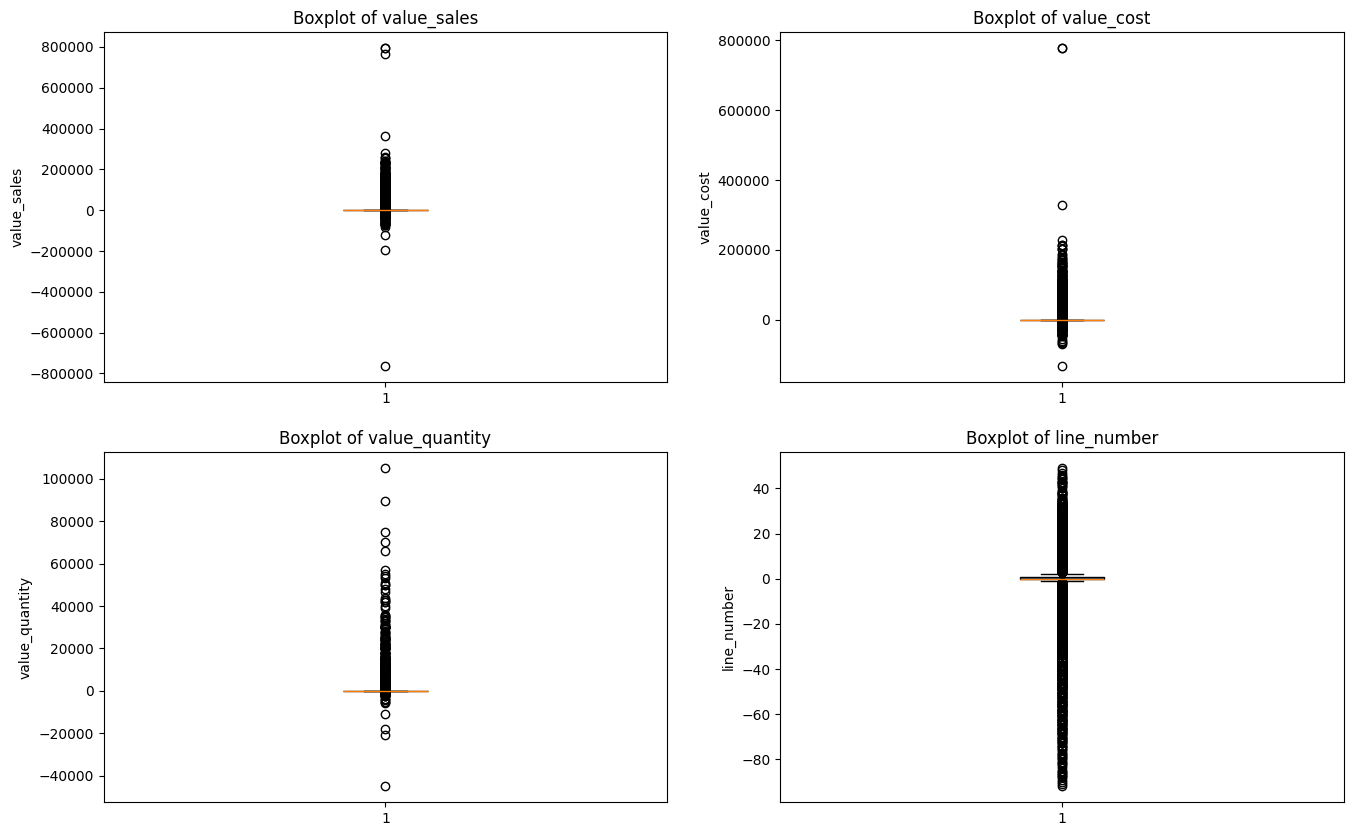

In [39]:
#Investigate the negative values in value columns

# Count negative values
print("NEGATIVE VALUE COUNTS:")
for var in ['line_number', 'value_sales', 'value_cost', 'value_quantity']:
    neg_count = (df[var] < 0).sum()
    print(f"{var}: {neg_count} negative values ({neg_count/len(df)*100:.1f}%)")

# Boxplot to visualize negatives
num_vars = ['value_sales', 'value_cost', 'value_quantity', 'line_number']

plt.figure(figsize=(16,10))
for idx, i in enumerate(num_vars):
    plt.subplot(2,2,idx+1)
    plt.boxplot(df[i], patch_artist=True)
#     sns.boxplot(x='abc_class_volume', y=i, data=data)
    plt.title(f'Boxplot of {i}')
    plt.ylabel(i)
plt.show()

In [40]:
# Analyze order types for negative records
negative_mask = (df['value_sales'] < 0) | (df['value_cost'] < 0) | (df['value_quantity'] < 0) | (df['line_number'] < 0)
negative_data = df[negative_mask]

# Show order type counts
print("Order type counts for negative values:")
print(negative_data['order_type_code'].value_counts())

# Show business chain, order type, and customer district code involved in negative transactions
print("\nNegative values by business chain and order type:")
business_chain_analysis = negative_data.groupby(['business_chain_l1_code', 'business_chain_l1_name', 'order_type_code', 'customer_district_code']).size().sort_values(ascending=False)
print(business_chain_analysis.head(15))  # Top 15 combinations

Order type counts for negative values:
order_type_code
NOR    55188
CRR    40515
CDG     9367
NOH     8557
CRD     2113
CPR      305
PMO       34
SPC        1
Name: count, dtype: int64

Negative values by business chain and order type:
business_chain_l1_code  business_chain_l1_name         order_type_code  customer_district_code
INTERCO                 InterGlobal Trading            NOR              720                       55188
                                                       NOH              720                        8557
MED                     Metro Electrical Distributors  CRR              400                        4317
BPS                     BrightPower Solutions          CRR              300                        3866
MED                     Metro Electrical Distributors  CRR              200                        3170
                                                                        300                        2520
NES                     NextGen Electrical So

Insights:
- The order types with negative sales, cost, quantity, or line number are the following:
  - NOR: Normal Order
  - CRR: Credit Good Returns
  - CDG: Credit Damaged Goods Not Returned
  - NOH: Normal Order Head Office Sales
  - CRD:  Credit Price Only
  - ZCG: Credit Goods Return - Pnz Only
  - CPR: Credit Project Goods Return
  - PMO: Project Order - Moonlighting
  - SPC: Specialty Order
- The negative values are legitimate transactions.
  - The NOR and NOH orders are intercompany sales (customer district code - 720). These transactions are internal and may have different business rules applicable to them. They will be kept in a separate dataset to avoid skewing the profitability analysis on external customers.
  - The credit/return orders (CRR, CDG, CRD, ZCG, CPR) will also be separated as they are return/refunds and not new sales. Including them in the sales analysis will affect the pattern of regular sales.

In [41]:
#Separate the returns/credits and intercompany sales
# 1. Returns/Credits (both order types AND negative values)
returns_mask = (
    df['order_type_code'].isin(['CRR', 'CDG', 'CRD', 'ZCG', 'CPR', 'PMO', 'SPC']) |
    (df['value_sales'] < 0) |
    (df['value_cost'] < 0) |
    (df['value_quantity'] < 0)
)
returns_df = df[returns_mask].copy()

# 2. Intercompany (from remaining records)
remaining_df = df[~returns_mask]
intercompany_mask = (
    (remaining_df['customer_district_code'] == 720) |
    (remaining_df['business_chain_l1_code'] == 'INTERCO')
)
intercompany_df = remaining_df[intercompany_mask].copy()

# 3. main dataset: Clean customer sales
clean_df = remaining_df[~intercompany_mask].copy()

In [42]:
# Verify no actual negative values in clean_df
print("Actual negative values in clean_df:")
for col in ['value_sales', 'value_cost', 'value_quantity']:
    neg_count = (clean_df[col] < 0).sum()
    print(f"{col}: {neg_count} negative values")

Actual negative values in clean_df:
value_sales: 0 negative values
value_cost: 0 negative values
value_quantity: 0 negative values


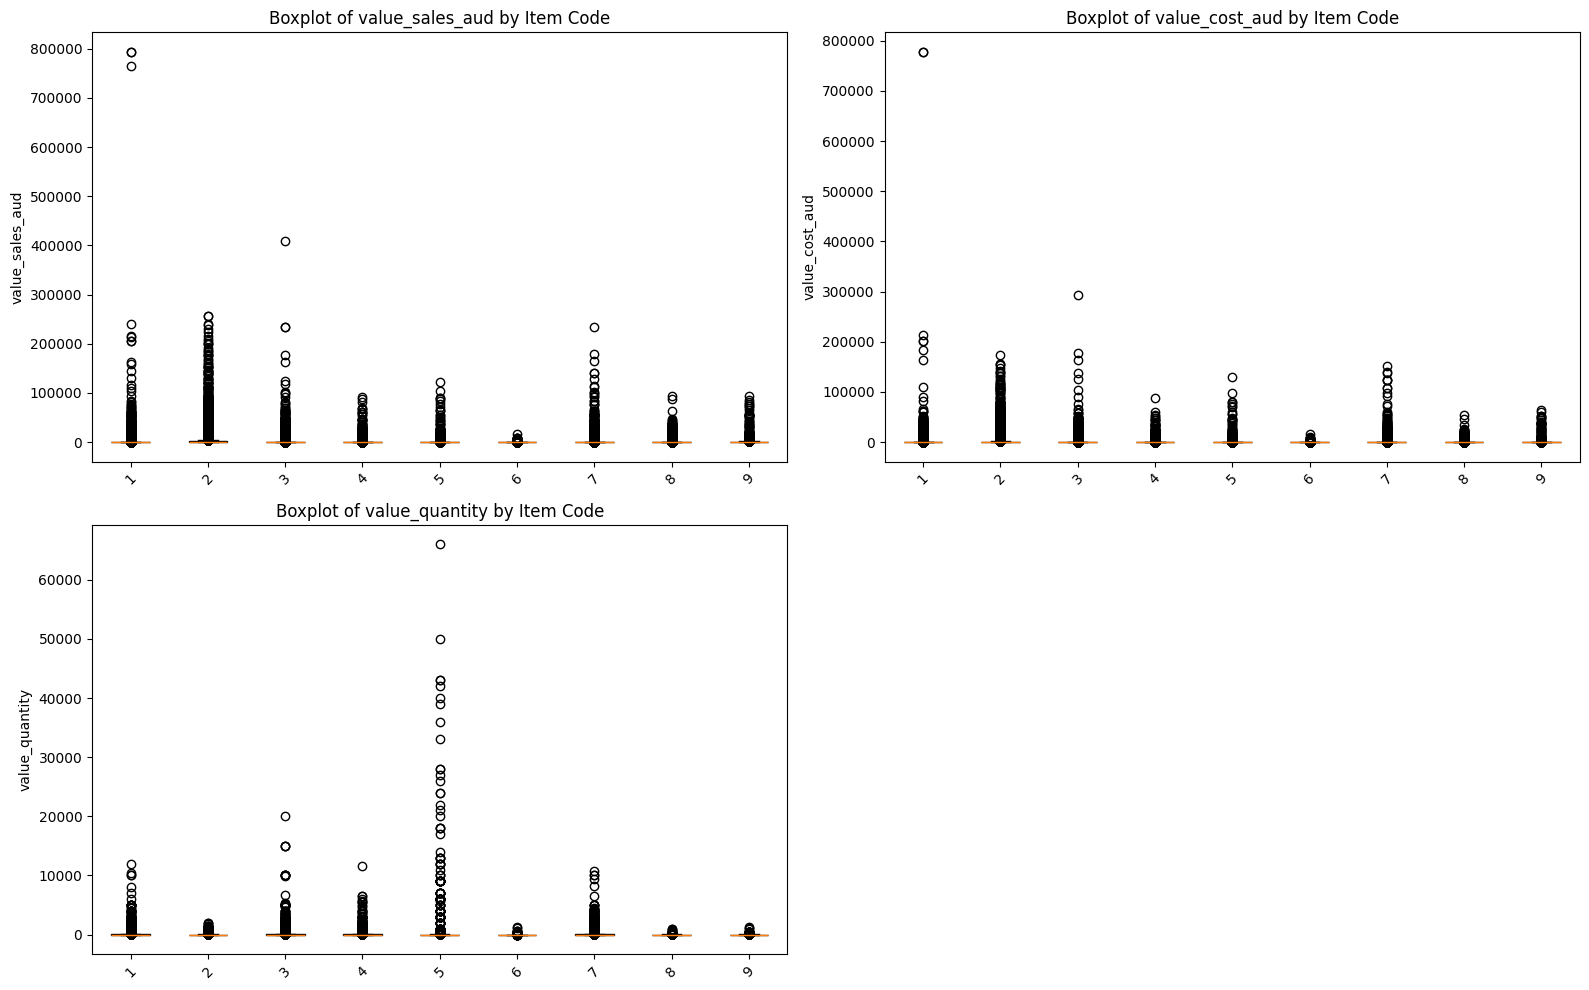

In [43]:
#After separating the negative values, we check for outliers in key value columns using clean_df.
#We use the aud-converted value sales and value cost for a simplified and streamlined analysis.
#Item code is used to group the value columns on the account that items are varied in terms of pricing and cost.
#Additionally, item_code is deemed to capture the variances in the value columns more concisely and more precisely
#than other item-related groupings (e.g. item_class_code with 205 unique values) and other categories with more broader groupings like light_source.

num_cols = ['value_sales_aud', 'value_cost_aud', 'value_quantity']

plt.figure(figsize=(16, 10))
for idx, var in enumerate(num_cols):
    plt.subplot(2, 2, idx+1)
    # Group by item_type and create boxplot
    data_to_plot = [clean_df[clean_df['item_type'] == code][var] for code in clean_df['item_type'].unique()]
    plt.boxplot(data_to_plot, patch_artist=True)
    plt.title(f'Boxplot of {var} by Item Code')
    plt.ylabel(var)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# Handle outliers by item_type group median
num_cols = ['value_sales_aud', 'value_cost_aud', 'value_quantity']
for col in num_cols:
    for item_type, group in clean_df.groupby('item_type'):
        Q1 = group[col].quantile(0.25)
        Q3 = group[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mask = (clean_df['item_type'] == item_type) & ((clean_df[col] < lower) | (clean_df[col] > upper))
        clean_df.loc[mask, col] = group[col].median()

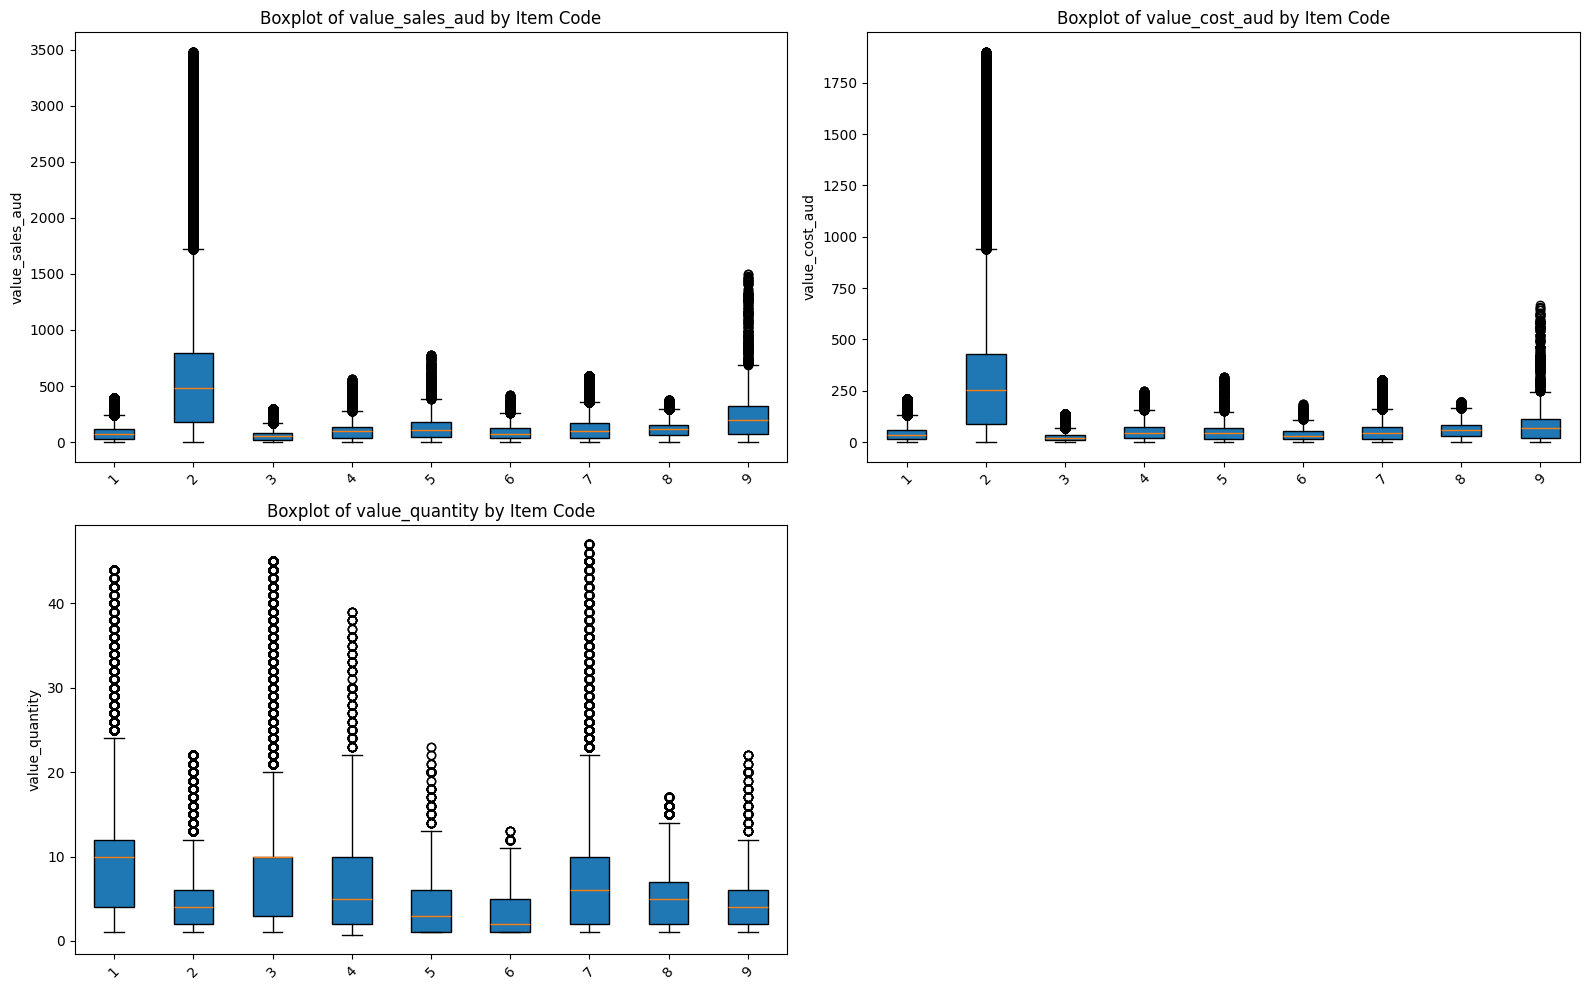

In [45]:
#Visualize after outlier treatment
num_cols = ['value_sales_aud', 'value_cost_aud', 'value_quantity']
plt.figure(figsize=(16, 10))
for idx, var in enumerate(num_cols):
    plt.subplot(2, 2, idx+1)
    # Group by item_type and create boxplot
    data_to_plot = [clean_df[clean_df['item_type'] == code][var] for code in clean_df['item_type'].unique()]
    plt.boxplot(data_to_plot, patch_artist=True)
    plt.title(f'Boxplot of {var} by Item Code')
    plt.ylabel(var)
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
#check for skewness
num_cols = ['value_sales_aud', 'value_cost_aud', 'value_quantity']
for col in num_cols:
    skewness = clean_df[col].skew()
    print(f"{col}: {skewness:.2f}")

value_sales_aud: 7.12
value_cost_aud: 7.30
value_quantity: 1.59


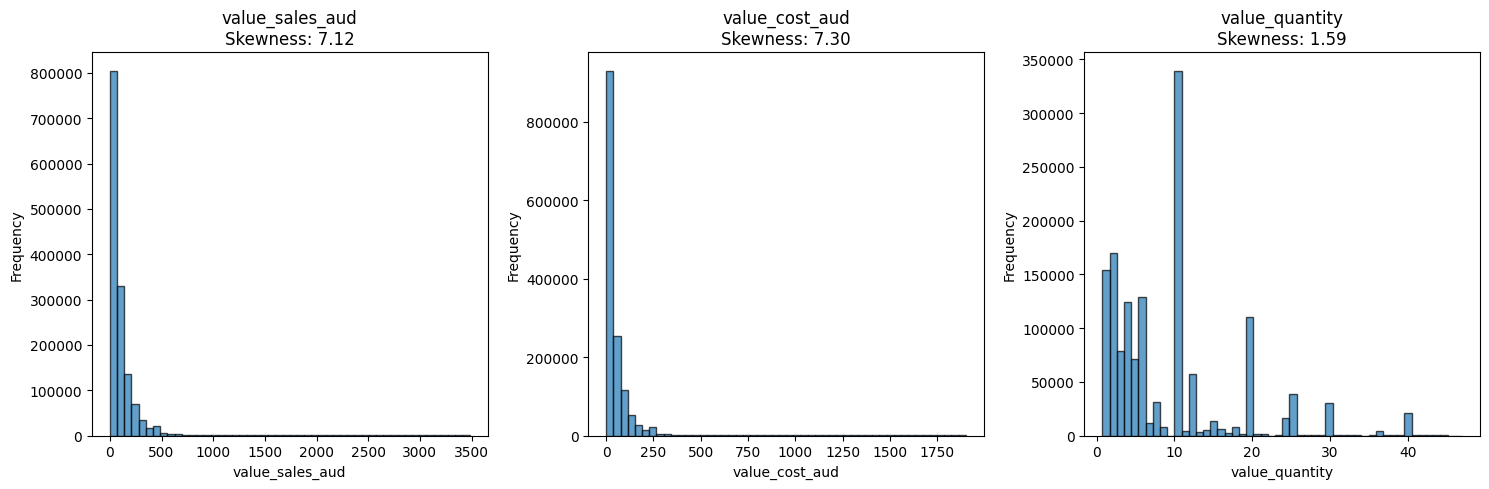

In [47]:
#visualize skewness
num_cols = ['value_sales_aud', 'value_cost_aud', 'value_quantity']
plt.figure(figsize=(15, 5))
for idx, col in enumerate(num_cols):
    plt.subplot(1, 3, idx+1)
    plt.hist(clean_df[col], bins=50, edgecolor='black', alpha=0.7)
    plt.title(f'{col}\nSkewness: {clean_df[col].skew():.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [48]:
# Apply log transformation (log1p handles zeros)
clean_df['log_sales'] = np.log1p(clean_df['value_sales_aud'])
clean_df['log_cost'] = np.log1p(clean_df['value_cost_aud'])
clean_df['log_quantity'] = np.log1p(clean_df['value_quantity'])

In [49]:
# Check new skewness
print("Skewness after log transformation:")
print(f"log_sales: {clean_df['log_sales'].skew():.2f}")
print(f"log_cost: {clean_df['log_cost'].skew():.2f}")
print(f"log_quantity: {clean_df['log_quantity'].skew():.2f}")

Skewness after log transformation:
log_sales: 0.14
log_cost: 0.22
log_quantity: -0.01


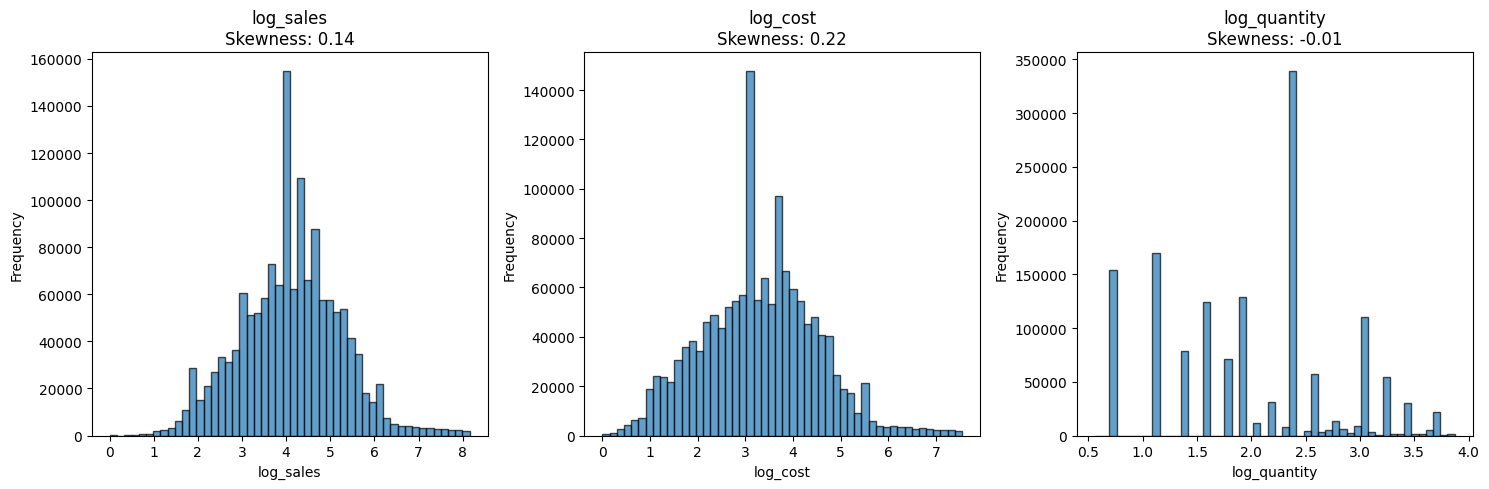

In [50]:
# Visualize after log transformation
log_cols = ['log_sales', 'log_cost', 'log_quantity']

plt.figure(figsize=(15, 5))
for idx, col in enumerate(log_cols):
    plt.subplot(1, 3, idx+1)
    plt.hist(clean_df[col], bins=50, edgecolor='black', alpha=0.7)
    plt.title(f'{col}\nSkewness: {clean_df[col].skew():.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Answer Section 2: Exploratory Insights (all the codes in one cell - do not insert extra cells)

## section 2.1 Sales and Profit Margin Trend by Light Source

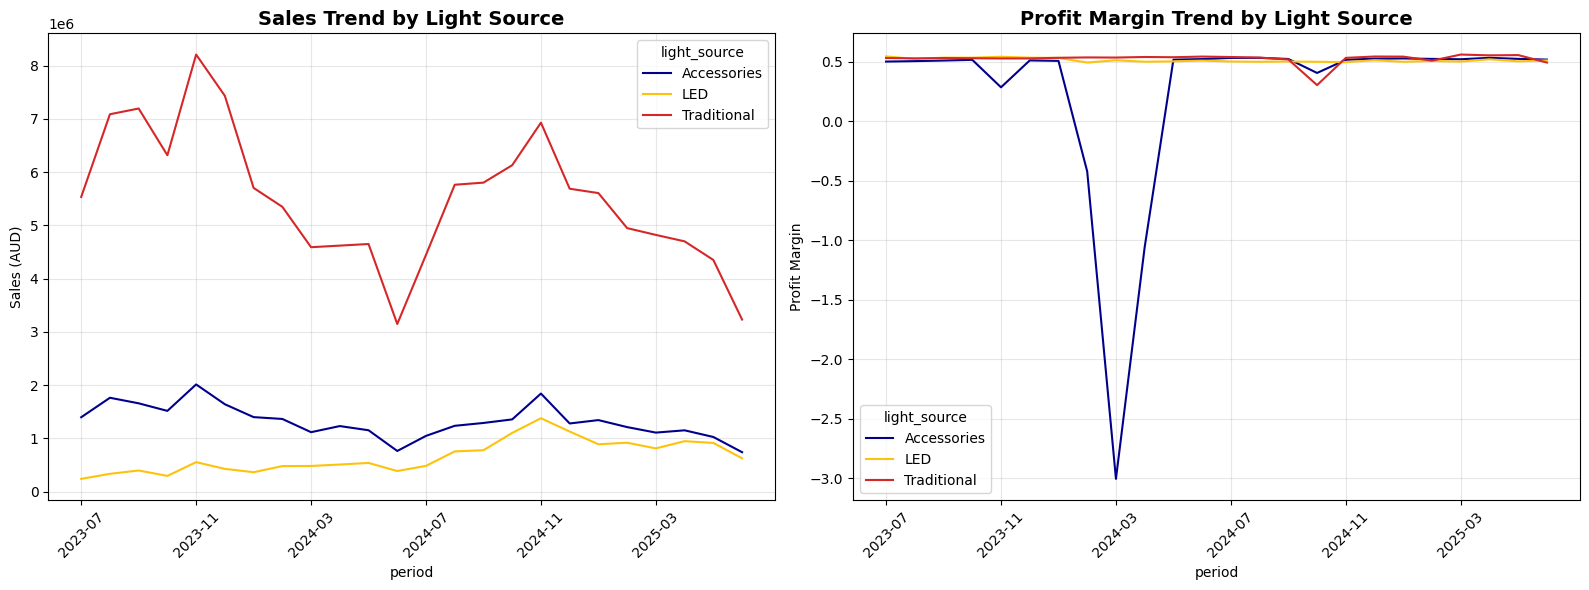

Explanation
Method Used: This visualization employs time series line charts with data aggregated by fiscal period (year-month) and light source type. For sales, we used sum aggregation to show total revenue volume, while for profit margin we used mean aggregation to display average profitability percentages.
Insights: Although Traditional light source has the highest sales range, but the most fluctuative. Overall profit margin is also at the similar range, except Accessories which had a negative margin during a certain time, but has recovered afterwards.
Importance to Management: Traditional light source products has always become the cash cows for the company; therefore, to create a balance, Luminatech must formulate a optimum strategy to maximize the opportunities for both LED & Accesorries products.


In [51]:
# Create profit margin column
clean_df['profit_margin'] = (clean_df['value_sales_aud'] - clean_df['value_cost_aud']) / clean_df['value_sales_aud']

# Create side-by-side visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Custom color palette
custom_colors = ['#01008C', '#FDC30B', '#d62728']  # Dark blue, orange/yellow, red

# Left: Sales trend by light source
sales_trend = clean_df.groupby(['fiscal_year', 'fiscal_month', 'light_source'])['value_sales_aud'].sum().reset_index()
sales_trend['period'] = sales_trend['fiscal_year'].astype(str) + '-' + sales_trend['fiscal_month'].astype(str).str.zfill(2)

sns.lineplot(data=sales_trend, x='period', y='value_sales_aud', hue='light_source', ax=ax1, palette=custom_colors)
ax1.set_title('Sales Trend by Light Source', fontsize=14, fontweight='bold')
ax1.set_ylabel('Sales (AUD)')
ax1.tick_params(axis='x', rotation=45)
ax1.set_xticks(ax1.get_xticks()[::4])
ax1.grid(True, alpha=0.3)  # Add grid

# Right: Profit margin trend by light source
pm_trend = clean_df.groupby(['fiscal_year', 'fiscal_month', 'light_source'])['profit_margin'].mean().reset_index()
pm_trend['period'] = pm_trend['fiscal_year'].astype(str) + '-' + pm_trend['fiscal_month'].astype(str).str.zfill(2)

sns.lineplot(data=pm_trend, x='period', y='profit_margin', hue='light_source', ax=ax2, palette=custom_colors)
ax2.set_title('Profit Margin Trend by Light Source', fontsize=14, fontweight='bold')
ax2.set_ylabel('Profit Margin')
ax2.tick_params(axis='x', rotation=45)
ax2.set_xticks(ax2.get_xticks()[::4])
ax2.grid(True, alpha=0.3)  # Add grid

plt.tight_layout()
plt.show()

print(
    "Explanation\n"
    "Method Used: This visualization employs time series line charts with data aggregated by fiscal period (year-month) and light source type. For sales, we used sum aggregation to show total revenue volume, while for profit margin we used mean aggregation to display average profitability percentages.\n"
    "Insights: Although Traditional light source has the highest sales range, but the most fluctuative. Overall profit margin is also at the similar range, except Accessories which had a negative margin during a certain time, but has recovered afterwards.\n"
    "Importance to Management: Traditional light source products has always become the cash cows for the company; therefore, to create a balance, Luminatech must formulate a optimum strategy to maximize the opportunities for both LED & Accesorries products."
    )

## section 2.2 Profit Contribution by Customer District

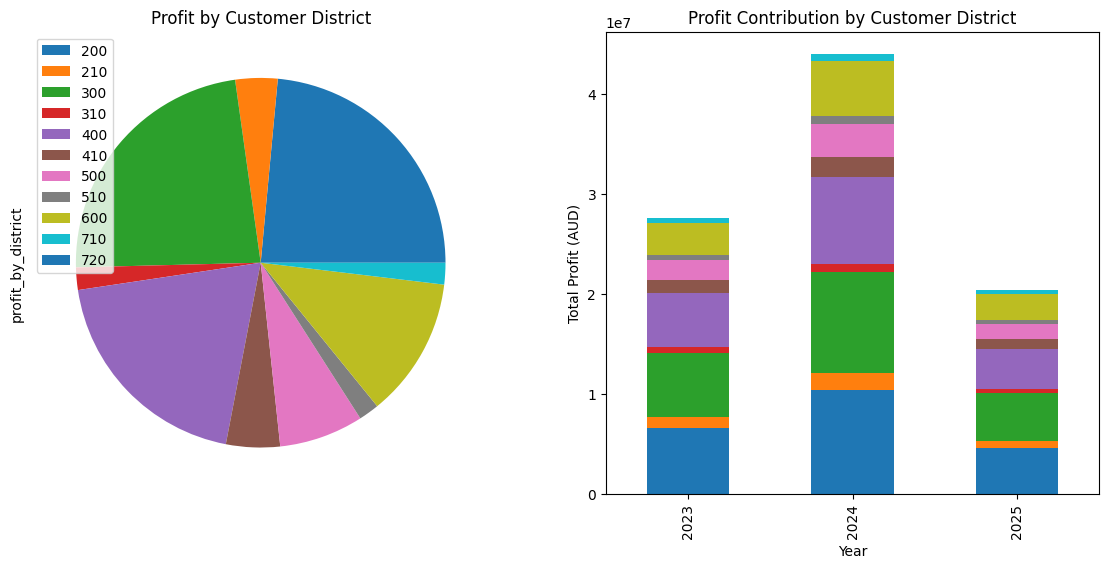

Explanation
Method Used: This visualization combines a pie chart and stacked bar chart to analyze profit distribution across customer districts. The pie chart shows the proportional contribution of each district to total profits using sum aggregation, while the stacked bar chart displays the profit contributions by district across fiscal years.
Insights: Three highest contributors of profit are from District 200 (Sydney), 300 (Melbourne), and 400 (Brisbane), accounting for >50% from the total.Importance to Management: Management should prioritize on retaining their position at the top three districts, while also developing key strategies from the lower contributors (310 - Tasmania, 510 - Darwin, 710 - Head Office)


In [52]:
# Calculate profit by customer district
clean_df['profit_by_district'] = clean_df['value_sales_aud'] - clean_df['value_cost_aud']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie Chart
plt.subplot(1,2,1)
prof_by_cus_dis = clean_df.groupby('customer_district_code')['profit_by_district'].sum()
prof_by_cus_dis.plot.pie(ax=axes[0], y='customer_district_code', legend=True, labels=None, title="Profit by Customer District")

#Bar Chart
plt.subplot(1,2,2)
prof_by_year_cus_dis = clean_df.groupby(['fiscal_year','customer_district_code'], observed=False)['profit_by_district'].sum().unstack()
prof_by_year_cus_dis.plot.bar(ax=axes[1], stacked=True, legend=False)
plt.xlabel("Year")
plt.ylabel("Total Profit (AUD)")
plt.title("Profit Contribution by Customer District")
plt.show()

print(
    "Explanation\n"
    "Method Used: This visualization combines a pie chart and stacked bar chart to analyze profit distribution across customer districts. The pie chart shows the proportional contribution of each district to total profits using sum aggregation, while the stacked bar chart displays the profit contributions by district across fiscal years.\n"
    "Insights: Three highest contributors of profit are from District 200 (Sydney), 300 (Melbourne), and 400 (Brisbane), accounting for >50% from the total."
    "Importance to Management: Management should prioritize on retaining their position at the top three districts, while also developing key strategies from the lower contributors (310 - Tasmania, 510 - Darwin, 710 - Head Office)"
    )

## section 2.3 Business Chain Performance - Cost Efficiency, Revenue Contribution, Order Value

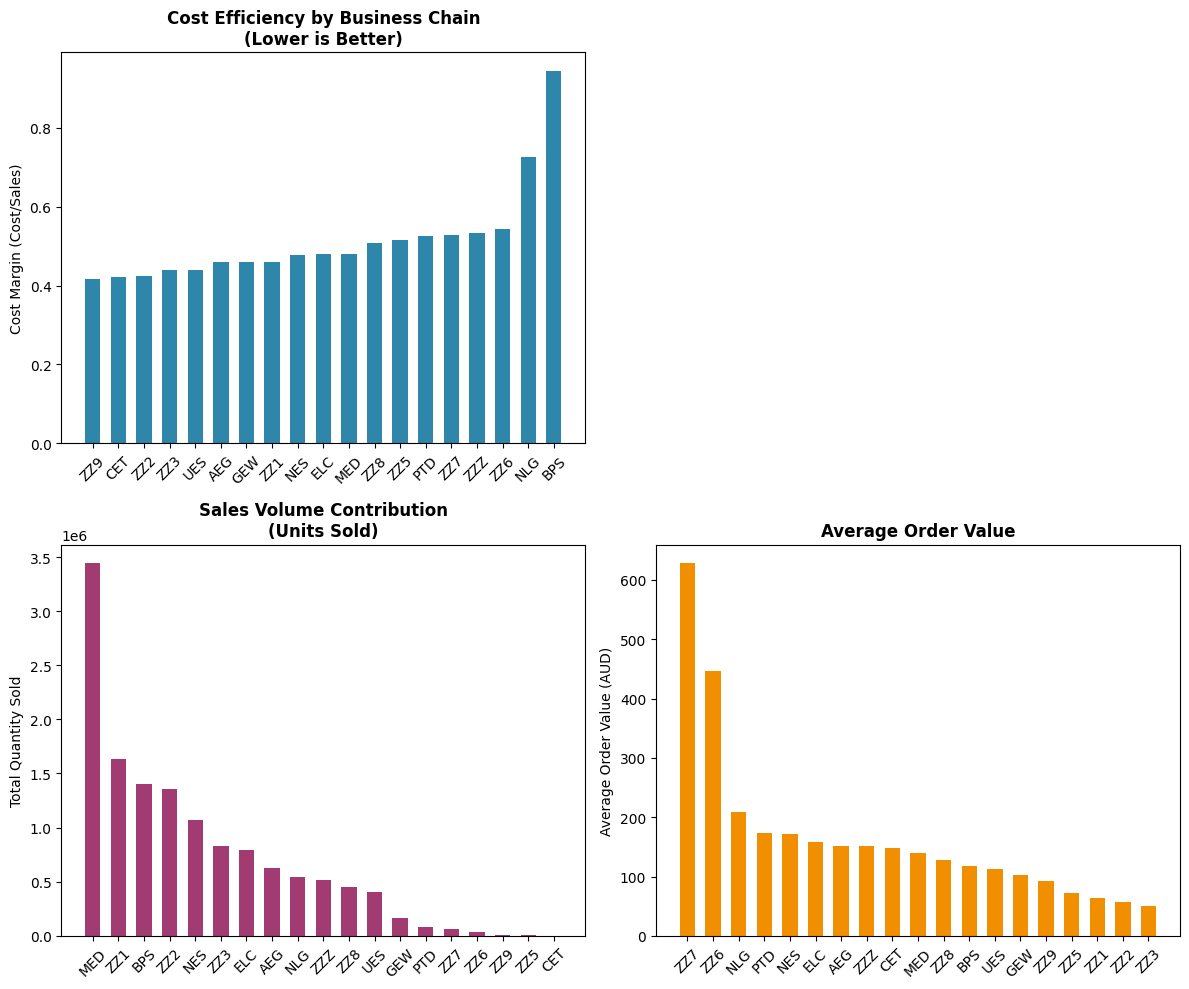

Explanation
Method Used: This visualization uses the bar chart to analyze the performance of each business chain through three key indicators: cost efficiency (cost to sales ratio), total quantity sold, and average sales valueInsights: Overall cost margin is on the lower side (0.4%-0.5%) except for NLG and BPS. For the sales quantity, MED's total is two times higher compared to the others. Additionally, ZZ7 and ZZ6 have a significantly higher order value compared to the others.Importance to Management: Although achieving a high sales is important, however it should also be balanced with the ability on maintaining cost efficiency and balance between the setting of a good pricing strategy and high sales volume to achieve a sustained performance. In addition, both BPS and NLG should receive operational reviews.


In [53]:
clean_df['cost_margin'] = clean_df['value_cost_aud'] / clean_df['value_sales_aud']
# Create subplots
fig = plt.figure(figsize=(12, 10))

# Top: Cost Efficiency
ax1 = plt.subplot(2, 2, 1)
cost_by_chain = clean_df.groupby('business_chain_l1_code')['cost_margin'].mean().sort_values()
bars1 = ax1.bar(cost_by_chain.index, cost_by_chain.values, color='#2E86AB', width=0.6)
ax1.set_title('Cost Efficiency by Business Chain\n(Lower is Better)', fontweight='bold')
ax1.set_ylabel('Cost Margin (Cost/Sales)')
ax1.tick_params(axis='x', rotation=45)

# Bottom Left: Sales Volume (Quantity)
ax2 = plt.subplot(2, 2, 3)
quantity_by_chain = clean_df.groupby('business_chain_l1_code')['value_quantity'].sum().sort_values(ascending=False)
bars2 = ax2.bar(quantity_by_chain.index, quantity_by_chain.values, color='#A23B72', width=0.6)
ax2.set_title('Sales Volume Contribution\n(Units Sold)', fontweight='bold')
ax2.set_ylabel('Total Quantity Sold')
ax2.tick_params(axis='x', rotation=45)

# Bottom Right: Average Order Value
ax3 = plt.subplot(2, 2, 4)
aov_by_chain = clean_df.groupby('business_chain_l1_code')['value_sales_aud'].mean().sort_values(ascending=False)
bars3 = ax3.bar(aov_by_chain.index, aov_by_chain.values, color='#F18F01', width=0.6)
ax3.set_title('Average Order Value', fontweight='bold')
ax3.set_ylabel('Average Order Value (AUD)')
ax3.tick_params(axis='x', rotation=45)

# Remove the empty subplot (position 2,2)
fig.delaxes(plt.subplot(2, 2, 2))

plt.tight_layout()
plt.show()

print(
    "Explanation\n"
    "Method Used: This visualization uses the bar chart to analyze the performance of each business chain through three key indicators: cost efficiency (cost to sales ratio), total quantity sold, and average sales value"
    "Insights: Overall cost margin is on the lower side (0.4%-0.5%) except for NLG and BPS. For the sales quantity, MED's total is two times higher compared to the others. Additionally, ZZ7 and ZZ6 have a significantly higher order value compared to the others."
    "Importance to Management: Although achieving a high sales is important, however it should also be balanced with the ability on maintaining cost efficiency and balance between the setting of a good pricing strategy and high sales volume to achieve a sustained performance. In addition, both BPS and NLG should receive operational reviews."
    )

## section 2.4 (all the codes in one cell - do not insert extra cells)

/tmp/ipython-input-260793599.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['segment', 'customer_district_code'])['customer_code']


District × Segment (head):
customer_district_code  200  210  300  310  400  410  500  510  600  710  720
segment                                                                      
Weekly                  635   73  519   57  451   66  216   26  260   46    0
Monthly                 171    4  110    9   80   17   49    6   63   31    1
Quarterly                74    1   67    3   33   14   22    2   28   26    0
Yearly                   22    1   19    0   11    2   11    0    7    5    0
Infrequent                2    0    3    0    1    0    0    0    0    1    0


/tmp/ipython-input-260793599.py:93: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['period', 'segment'])['customer_code']


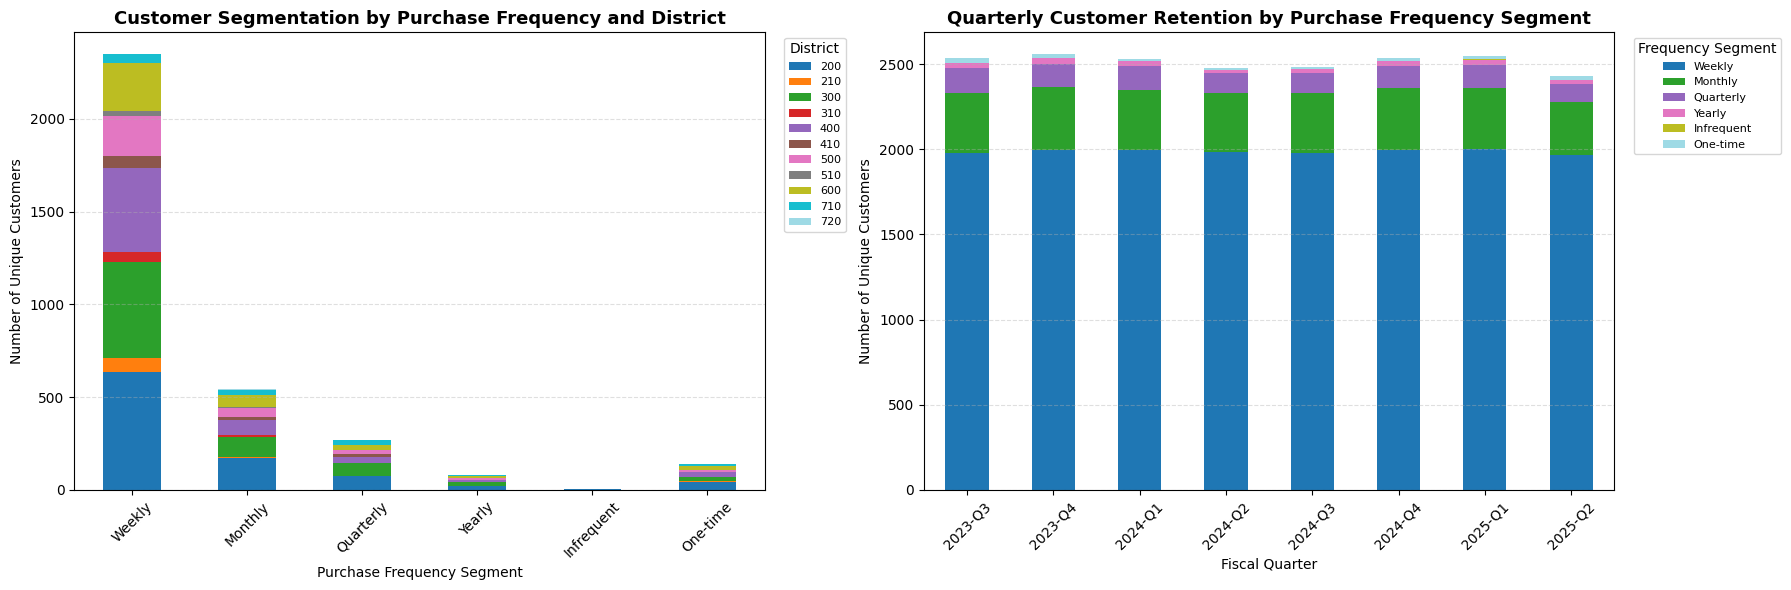

 Explanation:

 1 Chart: Customer Segmentation by Purchase Frequency and District
Method Used: Grouped customers by purchase frequency segment (Weekly, Monthly, Quarterly, Yearly, and One-time) and counted unique customer codes within each district using a stacked bar chart.
Insights: This shows how customer purchasing behavior varies by geographic district. For example, some frequent (Weekly/Monthly) have higher proportions of buyers from some districts.
Importance to Management: Helps identify strong vs. weak customer bases geographically. Management can target low-engagement districts with loyalty campaigns or improve service accessibility in areas with high one-time buyers.

 2 Chart: Quarterly Customer Retention by Purchase Frequency Segment
Method Used: Counted unique customers per fiscal quarter, grouped by purchase frequency segment, displayed as a stacked bar chart over time.
Insights: Reveals consistent retention trends across quarters, Weekly and Monthyly customers made up m

In [54]:
# 0) Parameters
segment_order = ['Weekly', 'Monthly', 'Quarterly', 'Yearly', 'Infrequent', 'One-time']
seg_dtype = pd.api.types.CategoricalDtype(categories=segment_order, ordered=True)

# 1) Minimal hygiene & dtype fixes
df_ret = clean_df.copy()  # keep original df safe

# Create fiscal period
df_ret['fiscal_quarter'] = ((df_ret['fiscal_month'] - 1) // 3 + 1).astype('Int64')
df_ret['period'] = df_ret['fiscal_year'].astype(str) + '-Q' + df_ret['fiscal_quarter'].astype(str)

# Create a lean customer_retention table (one row per customer)
customer_retention = (
    df_ret[['customer_code']]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Merge district codes (fill unknowns for plotting)
customer_retention = customer_retention.merge(
    df_ret[['customer_code', 'customer_district_code']].drop_duplicates(),
    on='customer_code',
    how='left'
)
customer_retention['customer_district_code'] = customer_retention['customer_district_code'].fillna('Unknown')

# 4) Compute purchase frequency per customer
# Sort to compute time deltas properly
tmp = df_ret.sort_values(['customer_code', 'invoice_date'])

# Count invoices per customer (to detect one-timers)
cust_counts = (
    tmp.groupby('customer_code', dropna=False)['invoice_date']
       .agg(n_orders='count')
       .reset_index()
)

# Average days between orders (only meaningful if n_orders > 1)
avg_gap = (
    tmp.groupby('customer_code', dropna=False)['invoice_date']
       .apply(lambda x: x.diff().mean().days if len(x) > 1 else np.nan)
       .reset_index(name='avg_days_between_orders')
)

customer_freq = (
    cust_counts.merge(avg_gap, on='customer_code', how='left')
    .assign(
        # Bin frequency only for customers with 2+ orders
        segment=lambda d: pd.cut(
            d['avg_days_between_orders'],
            bins=[0, 7, 30, 90, 365, np.inf],
            labels=['Weekly', 'Monthly', 'Quarterly', 'Yearly', 'Infrequent'],
            include_lowest=True
        ).astype(object)
    )
)

# Mark true One-time customers (n_orders == 1)
customer_freq.loc[customer_freq['n_orders'] == 1, 'segment'] = 'One-time'
customer_freq['segment'] = customer_freq['segment'].astype(seg_dtype)

# 5) Merge segment back to the fact tables (avoid suffix collisions)
for col in ['segment']:
    df_ret.drop(columns=col, errors='ignore', inplace=True)
    customer_retention.drop(columns=col, errors='ignore', inplace=True)

df_ret = df_ret.merge(
    customer_freq[['customer_code', 'segment']], on='customer_code', how='left'
)
customer_retention = customer_retention.merge(
    customer_freq[['customer_code', 'segment']], on='customer_code', how='left'
)

# 6) Build the two pivot tables

# A) District × Segment (unique customers)
district_segment = (
    customer_retention
    .groupby(['segment', 'customer_district_code'])['customer_code']
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=segment_order)  # enforce segment order on index
)

print("District × Segment (head):")
print(district_segment.head())

# B) Period × Segment (unique customers per period)
# Prevent double counting within a period
period_unique = df_ret.drop_duplicates(['period', 'customer_code'])
customers_per_period_segment = (
    period_unique
    .groupby(['period', 'segment'])['customer_code']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=segment_order, fill_value=0)  # enforce column order
)

# Sort periods nicely if they are strings like '2024-Q1'
customers_per_period_segment = customers_per_period_segment.sort_index()

# 7) Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: District stacked by Segment
district_segment.plot(
    kind='bar',
    stacked=True,
    colormap='tab20',
    ax=axes[0]
)
axes[0].set_title('Customer Segmentation by Purchase Frequency and District', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Unique Customers')
axes[0].set_xlabel('Purchase Frequency Segment')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].legend(title='District', fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')

# Right: Period stacked by Segment
customers_per_period_segment.plot(
    kind='bar',
    stacked=True,
    colormap='tab20',
    ax=axes[1]
)
axes[1].set_title('Quarterly Customer Retention by Purchase Frequency Segment', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Unique Customers')
axes[1].set_xlabel('Fiscal Quarter')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].legend(title='Frequency Segment', fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

print(
    " Explanation:\n"
    "\n 1 Chart: Customer Segmentation by Purchase Frequency and District\n"
    "Method Used: Grouped customers by purchase frequency segment (Weekly, Monthly, Quarterly, Yearly, and One-time) and counted unique customer codes within each district using a stacked bar chart.\n"
    "Insights: This shows how customer purchasing behavior varies by geographic district. For example, some frequent (Weekly/Monthly) have higher proportions of buyers from some districts.\n"
    "Importance to Management: Helps identify strong vs. weak customer bases geographically. Management can target low-engagement districts with loyalty campaigns or improve service accessibility in areas with high one-time buyers.\n"
    "\n 2 Chart: Quarterly Customer Retention by Purchase Frequency Segment\n"
    "Method Used: Counted unique customers per fiscal quarter, grouped by purchase frequency segment, displayed as a stacked bar chart over time.\n"
    "Insights: Reveals consistent retention trends across quarters, Weekly and Monthyly customers made up most of the sales regardless of seasonality.\n"
    "Importance to Management: Enables tracking of customer retention health over time. Managers can assess the effectiveness of retention strategies, evaluate campaign timing, and prioritize improving conversion from one-time to repeat customers."
)

## Section 2.5 LuminaTech's Profit Margin vs. Industry Profit Margin

Null Hypothesis (H0): The mean profit margin of LuminaTech equals the industry benchmark (μ = 0.0556)
Alternative Hypothesis (Ha): The mean profit margin of LuminaTech differs from the industry benchmark (μ ≠ 0.0556)
Significance Level: 0.05
t-statistic: 32.47041572318383
p-value: 3.378449616718559e-231
Reject the null hypothesis. LuminaTech's profit margin significantly differs from the industry benchmark.


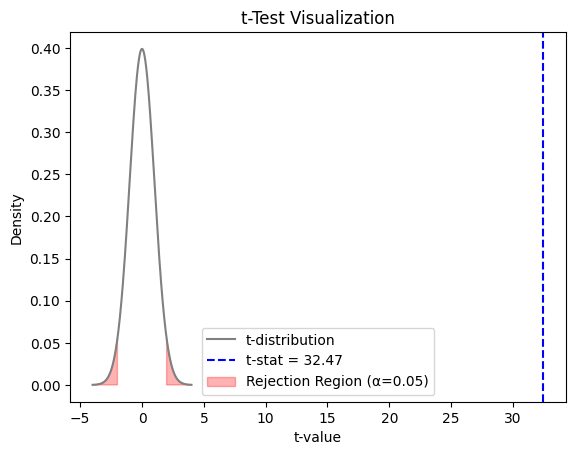

T-statistic: 32.470, p-value: 0.0000


In [55]:
# Step 1: State the Null Hypothesis and the Alternative Hypothesis
print("Null Hypothesis (H0): The mean profit margin of LuminaTech equals the industry benchmark (μ = 0.0556)")
print("Alternative Hypothesis (Ha): The mean profit margin of LuminaTech differs from the industry benchmark (μ ≠ 0.0556)")

# Step 2: Choose a Significance Level
alpha = 0.05
print(f"Significance Level: {alpha}")

# Step 3: Perform the One-Sample t-test and Find the p-value
# Use de-transformed profit margin for statistical testing

clean_df['value_sales_delog'] = np.expm1(clean_df['log_sales'])
clean_df['value_cost_delog'] = np.expm1(clean_df['log_cost'])

clean_df['profit_margin'] = (clean_df['value_sales_delog'] - clean_df['value_cost_delog']) / clean_df['value_sales_delog']

# Industry Benchmark
industry_benchmark = 0.0556

# Perform one-sample t-test (using already cleaned data)
t_statistic, p_value = stats.ttest_1samp(clean_df['profit_margin'], industry_benchmark)

print("t-statistic:", t_statistic)
print("p-value:", p_value)

# Step 4: Reject or Fail to Reject the Null Hypothesis
if p_value < alpha:
    print("Reject the null hypothesis. LuminaTech's profit margin significantly differs from the industry benchmark.")
else:
    print("Fail to reject the null hypothesis. No significant difference between LuminaTech's profit margin and industry benchmark.")

# Step 5: Generate t distribution curve
df_t = len(clean_df) - 1
x = np.linspace(-4, 4, 200)
y = stats.t.pdf(x, df_t)

plt.plot(x, y, label='t-distribution', color='gray')
plt.axvline(t_statistic, color='blue', linestyle='--', label=f't-stat = {t_statistic:.2f}')
plt.fill_between(x, y, where=(x > stats.t.ppf(0.975, df_t)) | (x < stats.t.ppf(0.025, df_t)),
                 color='red', alpha=0.3, label='Rejection Region (α=0.05)')
plt.title('t-Test Visualization')
plt.xlabel('t-value')
plt.ylabel('Density')
plt.legend()
plt.show()

print(f"T-statistic: {t_statistic:.3f}, p-value: {p_value:.4f}")

# Answer to Section 3: Test Sub Sample Differences (all the codes in one cell - do not insert extra cells)

## Section 3.1 Difference between the average sales volume of top 3 and bottom 3 business segments

In [56]:
# H0: There is no significant difference in average sales volume between the Top 3 and Bottom 3 business segments.
# H1: There is a significant difference in average sales volume between the two.

#Here, we grouped business areas based on how much total revenue they generate,
#and then tested whether those high-revenue areas also tend to sell significantly more (in units) than the low-revenue ones.

# Calculate the total sales revenue of each business area
area_sales_sum = clean_df.groupby('business_area_code', observed=True)['log_sales'].apply(lambda x: np.exp(x).sum()) #use original sales value

# Find the top 3 and bottom 3 business areas
top_3 = area_sales_sum.nlargest(3).index
bottom_3 = area_sales_sum.nsmallest(3).index

print("Top 3 Business Areas:", list(top_3))
print("Bottom 3 Business Areas:", list(bottom_3))

# Create two sample groups using log-transformed quantity
group_top3 = clean_df[clean_df['business_area_code'].isin(top_3)]['log_quantity'].dropna()
group_bottom3 = clean_df[clean_df['business_area_code'].isin(bottom_3)]['log_quantity'].dropna()

print("Top 3 sample size:", len(group_top3))
print("Bottom 3 sample size:", len(group_bottom3))

# Welch's t-test
t_stat, p_val = stats.ttest_ind(group_top3, group_bottom3, equal_var=False)

print(f"T-statistic = {t_stat:.3f}")
print(f"P-value = {p_val:.4f}")

# Convert back to original units for interpretation
top3_mean_units = np.exp(group_top3.mean())
bottom3_mean_units = np.exp(group_bottom3.mean())

print(f"\nTop 3 areas - Mean quantity: {top3_mean_units:.0f} units")
print(f"Bottom 3 areas - Mean quantity: {bottom3_mean_units:.0f} units")

alpha = 0.05
if p_val < alpha:
    print("\nReject H0: There is a significant difference in the average sales volume between the two groups")
    if group_top3.mean() > group_bottom3.mean():
        print("Top business areas have significantly higher sales volumes")
    else:
        print("Top business areas have significantly lower sales volumes")
else:
    print("\nFail to reject H0: There is no significant difference in the average sales volume between the two groups")

Top 3 Business Areas: ['SUR', 'LMP', 'COM']
Bottom 3 Business Areas: ['IAE', '930', '960']
Top 3 sample size: 1058850
Bottom 3 sample size: 55
T-statistic = 5.872
P-value = 0.0000

Top 3 areas - Mean quantity: 8 units
Bottom 3 areas - Mean quantity: 5 units

Reject H0: There is a significant difference in the average sales volume between the two groups
Top business areas have significantly higher sales volumes


## Section 3.2 Difference in the unit price of top 2 best selling technology groups

In [57]:
# Hypothesis Testing: Unit Price (Top 2 Best Selling Technology Groups)

# H0: There is no significant difference in the average unit selling price between the two best selling technology groups.
# H1: There is a significant difference in the average unit selling price between the two.

# Hypotheses
print("H0: No significant difference in average unit selling price between the top 2 best-selling technology groups.")
print("H1: There is a significant difference between the two.")

# Compute log unit price
clean_df["log_unit_price"] = clean_df["log_sales"] - clean_df["log_quantity"]

# Identify Top 2 Best-Selling Technology Groups (based on actual quantity - the np.exp converts it back)
tech_sales = clean_df.groupby("technology_group_code", observed=True)["log_quantity"].apply(lambda x: np.exp(x).sum())
top2_codes = tech_sales.nlargest(2).index
g1, g2 = top2_codes[0], top2_codes[1]
print(f"\nTop 2 best-selling technology groups: {g1}, {g2}")

# Extract Groups
s1 = clean_df.loc[clean_df["technology_group_code"] == g1, "log_unit_price"].dropna()
s2 = clean_df.loc[clean_df["technology_group_code"] == g2, "log_unit_price"].dropna()

print(f"{g1} sample size: {len(s1)}")
print(f"{g2} sample size: {len(s2)}")

# Welch's t-test
t_stat, p_val = stats.ttest_ind(s1, s2, equal_var=False)
print(f"\nT-statistic = {t_stat:.4f}")
print(f"P-value = {p_val:.4f}")

# Back-transform to original AUD for business interpretation
mean_price_g1 = np.exp(s1.mean())
mean_price_g2 = np.exp(s2.mean())

print(f"\nInterpretation in Original Units (AUD):")
print(f"{g1} - Mean unit price: ${mean_price_g1:.2f}")
print(f"{g2} - Mean unit price: ${mean_price_g2:.2f}")

# Decision
alpha = 0.05
if p_val < alpha:
    print("\nReject H0: Significant difference in average unit price between the two groups.")
else:
    print("\nFail to reject H0: No significant difference in average unit price between the two groups.")

if p_val < alpha:
    print("\nSignificance:")
    if s1.mean() > s2.mean():
        print(f"{g1} likely targets a premium market segment (${mean_price_g1:.2f})")
        print(f"{g2} targets a more price-sensitive, volume-driven market (${mean_price_g2:.2f})")
    else:
        print(f"{g2} likely targets a premium market segment (${mean_price_g2:.2f})")
        print(f"{g1} targets a more price-sensitive, volume-driven market (${mean_price_g1:.2f})")
else:
    print(f" No significant difference: {g1} and {g2} operate in similar pricing segments")
    print(f" Both priced roughly around ${mean_price_g1:.2f}–${mean_price_g2:.2f}")


H0: No significant difference in average unit selling price between the top 2 best-selling technology groups.
H1: There is a significant difference between the two.

Top 2 best-selling technology groups: SYLV, 78
SYLV sample size: 282263
78 sample size: 233102

T-statistic = 267.0974
P-value = 0.0000

Interpretation in Original Units (AUD):
SYLV - Mean unit price: $9.55
78 - Mean unit price: $3.90

Reject H0: Significant difference in average unit price between the two groups.

Significance:
SYLV likely targets a premium market segment ($9.55)
78 targets a more price-sensitive, volume-driven market ($3.90)


## Section 3.3 Profit margins of top 10 customer districts vs other districts

In [71]:
# Do the top 10 customer districts have significantly different profit margins compared to the other districts?

# Calculate profit margin properly (using original, not log-transformed values)
clean_df['profit_margin'] = (clean_df['value_sales_aud'] - clean_df['value_cost_aud']) / clean_df['value_sales_aud']

# Identify top 10 customer districts that bring the highest sales (using actual sales)
district_sales = clean_df.groupby('customer_district_code')['value_sales_aud'].sum().sort_values(ascending=False)
top_10_districts = district_sales.index[:10].tolist()
print('Top 10 districts:', top_10_districts)

# Separate top 10 and other customer districts
top_group = clean_df[clean_df['customer_district_code'].isin(top_10_districts)]['profit_margin'].dropna()
other_group = clean_df[~clean_df['customer_district_code'].isin(top_10_districts)]['profit_margin'].dropna()

# Hypotheses
print('H0: Mean profit margin of top 10 districts = that of other districts')
print('H1: Mean profit margin of top 10 districts ≠ that of other districts')

# Perform Welch’s t-test
import scipy.stats as st
t_statistic, p_value = st.ttest_ind(top_group, other_group, equal_var=False)

# Report
print('\nTwo-sample t-test: Profit Margin by Customer Districts Group')
print(f'Mean profit margin (top 10): {top_group.mean():.4f} ({top_group.mean()*100:.1f}%)')
print(f'Mean profit margin (others): {other_group.mean():.4f} ({other_group.mean()*100:.1f}%)')
print(f't-statistic: {t_statistic:.3f}')
print(f'p-value: {p_value:.4f}')

alpha = 0.05
if p_value < alpha:
    print('Conclusion: Reject H0: Top 10 districts have significantly different profit margins.')
else:
    print('Conclusion: Fail to reject H0: No significant difference in profit margins.')

print("The t-test shows that our top 10 sales-generating districts achieve slightly lower profit margins (47.1%) than the rest (60.4%),\n"
 "a statistically significant difference (p = 0.0009) and a negative t-statistic.\n"
  "This suggests that volume growth in these areas may come with margin trade-offs,"
  "potentially due to price discounts or cost structures (e.g. Bulk-purchase or loyalty discounts to high-volume customers)."
  "Therefore, management should review product mix and pricing strategies in these high-volume districts to ensure sustainable profitability.")

Top 10 districts: ['300', '200', '400', '600', '500', '410', '210', '310', '510', '710']
H0: Mean profit margin of top 10 districts = that of other districts
H1: Mean profit margin of top 10 districts ≠ that of other districts

Two-sample t-test: Profit Margin by Customer Districts Group
Mean profit margin (top 10): 0.4714 (47.1%)
Mean profit margin (others): 0.6044 (60.4%)
t-statistic: -3.465
p-value: 0.0009
Conclusion: Reject H0: Top 10 districts have significantly different profit margins.
The t-test shows that our top 10 sales-generating districts achieve slightly lower profit margins (47.1%) than the rest (60.4%),
a statistically significant difference (p = 0.0009) and a negative t-statistic.
This suggests that volume growth in these areas may come with margin trade-offs,potentially due to price discounts or cost structures (e.g. Bulk-purchase or loyalty discounts to high-volume customers).Therefore, management should review product mix and pricing strategies in these high-volume 

# Answer to Section 4: Inference (in this section, add as many cells as you need)

### Research Question: What factors significantly influence sales at LuminaTech?
Rationale: Sales revenue serves as the primary engine of business growth and market presence. It reflects not just the company's ability to generate transactions but also its market penetration, customer demand, and competitive positioning. Therefore, it signals the company's growth trajectory, market share, and revenue potential. For LuminaTech's decision makers, it is critical to understand what drives sales performance in order to make strategic decisions about resource allocation, market expansion, and growth initiatives that directly impact the company's top-line performance and competitive standing in the lighting industry.

## 4.1 Selection of Variables



**Business factors considered:**

- **cost (log_cost)**: Affects pricing of products and purchasing decision of customers.
- **quantity (log_quantity)**: Relates to the scale/volume of sales and could indicate market penetration, efficiency of order processing, etc.
- **business_area_code**: Relates to which segments of the markets are being catered to, also indicating penetration or reach.
- **customer_district_code**: Relates to geographic market reach.
- **light_source**: Shows the category of products by type of lighting. This could be relevant in broadly identifying customer preferences/needs that drive sales.
- **abc_class_code**: Shows product importance which could identify how products affect sales.
- **abc_class_volume**: Shows how product affect sales volume and contribution to sales.
- **technology_group_code**: Shows the brand and technology performance.
- **order_type_code**: Shows sales channel efficiency.
- **warehouse_code**: Relates to distribution network - how the company is able to fulfill geographic market demand.

**Handling of Categorical Variables** <br>
Given the volume of categorical values in each column, we deemed it impractical to encode all of them one-by-one separately since too many categories will be produced and this will demand more computational power. Moreover, categorical values that occur infrequently may not have enough data to draw reliable conclusions from and would just create noise rather than useful patterns. Consequently, this may result in overfitting. We handled this by just encoding the major categories that occur more frequently and then group the rest into "others."  

In [59]:
# Data Preparation & Encoding

df_model = clean_df.copy()
grouped_cols = ['business_area_code', 'customer_district_code', 'light_source', 'abc_class_code',
                'abc_class_volume', 'technology_group_code', 'order_type_code', 'warehouse_code']

encoding_stats = {}
grouped_business_factors = []

for col in grouped_cols:
    proportions = df_model[col].value_counts(normalize=True) * 100
    major_values = proportions[proportions >= 10].index
    mapping = {cat: cat if cat in major_values else 'Other' for cat in proportions.index}

    grouped_col_name = f'{col}_group'
    df_model.loc[:, grouped_col_name] = df_model[col].map(mapping)
    grouped_business_factors.append(grouped_col_name)

    encoding_stats[col] = {
        'original_categories': len(proportions),
        'major_categories': list(major_values),  # Store the actual names, not len()
        'others_proportion': proportions[~proportions.index.isin(major_values)].sum(),
        'mapping': mapping
    }

print("Category grouping completed:")
for col, stats in encoding_stats.items():
    # Get the actual major category names from the mapping
    major_names = list(stats['mapping'].keys())
    # Filter out 'Other' to get only the major categories
    major_categories = [name for name in major_names if stats['mapping'][name] == name]
    print(f"  {col}: {stats['original_categories']} → {len(major_categories)} major + Other")
    print(f"    Major categories: {major_categories}")

Category grouping completed:
  business_area_code: 27 → 2 major + Other
    Major categories: ['LMP', 'SUR']
  customer_district_code: 11 → 3 major + Other
    Major categories: ['300', '200', '400']
  light_source: 3 → 2 major + Other
    Major categories: ['Traditional', 'Accessories']
  abc_class_code: 10 → 6 major + Other
    Major categories: ['J', 'A', 'B', 'U', 'D', 'G']
  abc_class_volume: 10 → 2 major + Other
    Major categories: ['J', 'U']
  technology_group_code: 94 → 3 major + Other
    Major categories: ['SYLV', '78', 'CROM']
  order_type_code: 15 → 1 major + Other
    Major categories: ['NOR']
  warehouse_code: 48 → 2 major + Other
    Major categories: ['5N2', 'CN0']


In [60]:
# One-Hot Encoding
df_encoded = pd.get_dummies(df_model, columns=grouped_business_factors, drop_first=True)

# Convert encoded columns to integers
encoded_cols = [col for col in df_encoded.columns if col not in clean_df.columns]
df_encoded[encoded_cols] = df_encoded[encoded_cols].astype(int)

print(f"Encoded {len(encoded_cols)} variables")

Encoded 21 variables


## 4.2. Distribution Check and Correlation

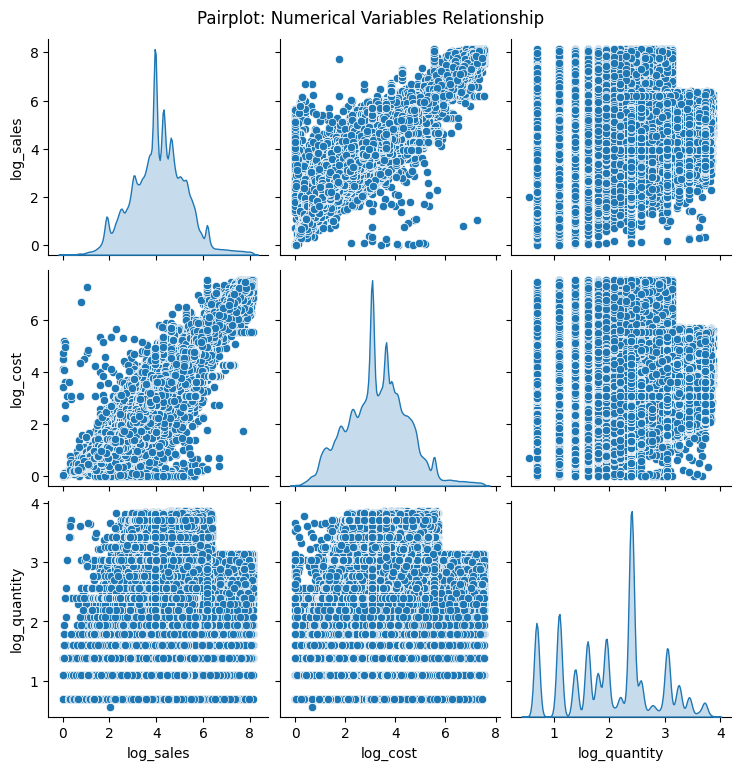

In [61]:
#Pairplot - Numerical Variables
numerical_vars = ['log_sales', 'log_cost', 'log_quantity']

sns.pairplot(df_model[numerical_vars], diag_kind='kde')
plt.suptitle('Pairplot: Numerical Variables Relationship', y=1.02)
plt.show()

**Pairplot Interpretation** <br>
In this pairplot, it is clear that cost is positively correlated with sales. Meanwhile, quantity shows a tiered horizontal/vertical line pattern. This may indicate that the relationship depends on factors like product and shows that at specific quantity tiers, different products have different price points which affect sales volume. The discrete nature of order quantities may have created these distinct tiers.

In [62]:
# Correlation Analysis

# Select key variables for correlation
correlation_vars = [
    'log_sales', 'log_cost', 'log_quantity',
    # Add categorical variables
    *[col for col in df_encoded.columns if any(x in col for x in [
        'business_area_code_group', 'customer_district_code_group', 'light_source_group',
        'abc_class_code_group', 'abc_class_volume_group', 'technology_group_code_group',
        'order_type_code_group', 'warehouse_code_group'
    ])]
]

# Calculate correlation matrix
corr_matrix = df_encoded[correlation_vars].corr()
print(corr_matrix['log_sales'].sort_values(ascending=False))

log_sales                             1.000000
log_cost                              0.938362
business_area_code_group_Other        0.247568
warehouse_code_group_Other            0.246415
abc_class_volume_group_Other          0.210651
order_type_code_group_Other           0.194937
abc_class_code_group_J                0.149614
light_source_group_Other              0.131122
technology_group_code_group_SYLV      0.125493
business_area_code_group_SUR          0.112515
log_quantity                          0.104055
technology_group_code_group_Other     0.083444
customer_district_code_group_Other    0.020285
customer_district_code_group_300      0.016105
abc_class_volume_group_U              0.007579
abc_class_code_group_U                0.007579
technology_group_code_group_CROM     -0.013622
customer_district_code_group_400     -0.023863
light_source_group_Traditional       -0.030736
abc_class_code_group_B               -0.048156
abc_class_code_group_G               -0.056684
abc_class_cod

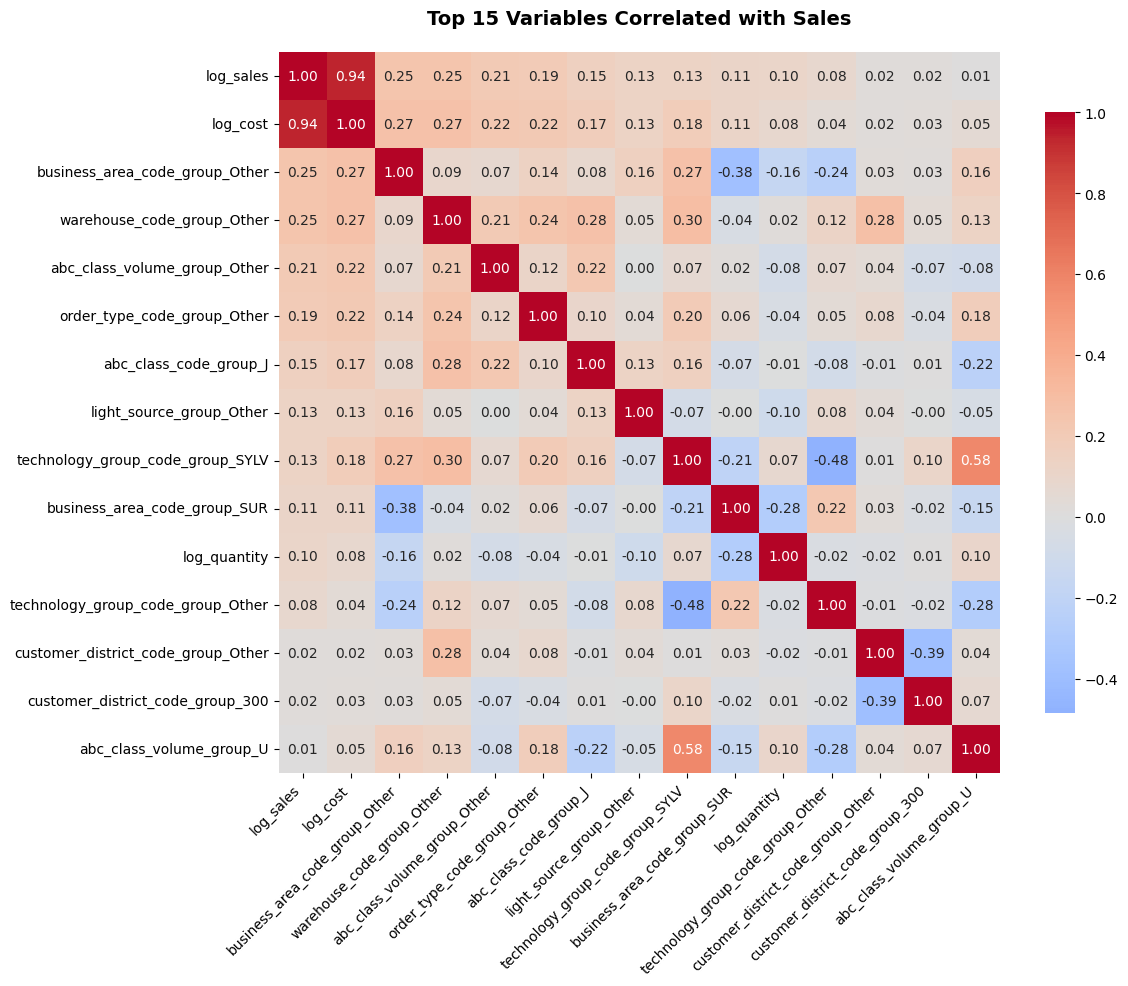


TOP 15 STRONGEST CORRELATIONS WITH SALES:
  log_cost: 0.938 (positive)
  business_area_code_group_Other: 0.248 (positive)
  warehouse_code_group_Other: 0.246 (positive)
  abc_class_volume_group_Other: 0.211 (positive)
  order_type_code_group_Other: 0.195 (positive)
  abc_class_code_group_J: 0.150 (positive)
  light_source_group_Other: 0.131 (positive)
  technology_group_code_group_SYLV: 0.125 (positive)
  business_area_code_group_SUR: 0.113 (positive)
  log_quantity: 0.104 (positive)
  technology_group_code_group_Other: 0.083 (positive)
  customer_district_code_group_Other: 0.020 (positive)
  customer_district_code_group_300: 0.016 (positive)
  abc_class_volume_group_U: 0.008 (positive)
  abc_class_code_group_U: 0.008 (positive)


In [63]:
#Correlation heatmap with only the top 15 variables

# Get top 15 variables most correlated with sales
sales_correlations = corr_matrix['log_sales'].sort_values(ascending=False)
top_corr_vars = sales_correlations.head(15).index.tolist()
focused_corr = df_encoded[top_corr_vars].corr()

# Heatmap with only top 15 variables
plt.figure(figsize=(12, 10))
sns.heatmap(focused_corr, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, cbar_kws={'shrink': 0.8})
plt.title('Top 15 Variables Correlated with Sales',
          fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print summary of strongest correlations
print("\nTOP 15 STRONGEST CORRELATIONS WITH SALES:")
for var, corr in sales_correlations.head(16).items():
    if var != 'log_sales':
        actual_corr = corr_matrix.loc['log_sales', var]
        direction = "positive" if actual_corr > 0 else "negative"
        print(f"  {var}: {actual_corr:.3f} ({direction})")

## 4.3. Multiple Linear Regression <br>
We used the top 15 most correlated variables as X variables.

In [64]:
# Select variables to include in the model
import statsmodels.api as sm

X_vars = [
    'log_cost',
    'log_quantity',
    'business_area_code_group_Other', 'warehouse_code_group_Other', 'abc_class_volume_group_Other',
    'order_type_code_group_Other', 'abc_class_code_group_J', 'light_source_group_Other',
    'technology_group_code_group_SYLV', 'warehouse_code_group_CN0', 'business_area_code_group_SUR',
    'technology_group_code_group_Other', 'abc_class_code_group_D', 'abc_class_code_group_Other',
    'abc_class_code_group_B'
]

print(f"Using {len(X_vars)} variables:")
for var in X_vars:
    print(f"  - {var}")

X = df_encoded[X_vars]
y = df_encoded['log_sales']
X = sm.add_constant(X)

Using 15 variables:
  - log_cost
  - log_quantity
  - business_area_code_group_Other
  - warehouse_code_group_Other
  - abc_class_volume_group_Other
  - order_type_code_group_Other
  - abc_class_code_group_J
  - light_source_group_Other
  - technology_group_code_group_SYLV
  - warehouse_code_group_CN0
  - business_area_code_group_SUR
  - technology_group_code_group_Other
  - abc_class_code_group_D
  - abc_class_code_group_Other
  - abc_class_code_group_B


In [65]:
# VIF Analysis
from statsmodels.stats.outliers_influence import variance_inflation_factor
print("\nVIF Analysis:")
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values('VIF', ascending=False).head(20))


VIF Analysis:
                              Feature        VIF
0                               const  21.284635
4          warehouse_code_group_Other   2.113046
9    technology_group_code_group_SYLV   1.968266
13             abc_class_code_group_D   1.685889
3      business_area_code_group_Other   1.668551
12  technology_group_code_group_Other   1.662979
7              abc_class_code_group_J   1.610644
11       business_area_code_group_SUR   1.588648
1                            log_cost   1.425729
2                        log_quantity   1.313952
15             abc_class_code_group_B   1.246138
10           warehouse_code_group_CN0   1.239469
14         abc_class_code_group_Other   1.232979
6         order_type_code_group_Other   1.160653
5        abc_class_volume_group_Other   1.149435
8            light_source_group_Other   1.093428


**VIF Analysis** <br>
All feature VIF scores are well below the threshold of 5, indicating no concerning multicollinearity in the regression model. No two variables are highly correlated with each other, indicating that each variable brings unique information. The model won't be confused by redundant predictors.

In [66]:
# Regression Model
model = sm.OLS(y, X).fit()
print("REGRESSION RESULTS SUMMARY")
print(model.summary())

REGRESSION RESULTS SUMMARY
                            OLS Regression Results                            
Dep. Variable:              log_sales   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                 7.519e+05
Date:                Sun, 02 Nov 2025   Prob (F-statistic):               0.00
Time:                        10:40:01   Log-Likelihood:            -6.8381e+05
No. Observations:             1454937   AIC:                         1.368e+06
Df Residuals:                 1454921   BIC:                         1.368e+06
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

**Model Fit Statistics**
- R-squared and adjusted r-squared shows that the model explains 88.7% of the variability in sales. The high explanatory power indicates a strong model fit.
- The significant F-statistic shows that the regression model is statistically significant overall ( 8.423e+05 or 842,300, p < 0.001), indicating that the included predictors jointly have a strong effect on sales.
  
**Coefficient Analysis**
- All the features included are statistically significant with p-values < 0.05.
- Since dependent and numeric predictors are log-transformed, we can approximate: For numeric variables: 1% increase in predictor → β% change in sales. For categorical variables: 100×(exp(β)−1)% change relative to base group or the group that has been dropped by the model to avoid dummy variable trap.
- So, holding other factors constant: <br>
  *positive coefficients:*
  - log_cost: 1% increase is associated with 0.88% increase in sales
  - log_quantity: 1% increase is associated with 0.066% increase in sales
  - business_area_code_group_Other: sells about 8% more than the reference group
  - business_area_code_group_SUR: sells about 7.7% more than the reference group
  - light_source_group_Other: sells about 2.1% more than reference group
  - abc_class_code_group_B: sells about 9.3% more than the reference group
  - abc_class_code_group_D: sells about 7.8% more than the reference group
  - abc_class_code_group_Other: sells about 7% more than the reference group
  - abc_class_volume_group_Other: “Other” volume groups have slightly higher sales
  - technology_group_code_group_Other: "Other technologies perform about 6.8% better than reference group
  - abc_class_code_group_J: performs about 2.6% higher than reference group <br>
 *negative coefficients:* <br>
  - technology_group_code_group_SYLV: has about 8% lower sales than the reference
  - warehouse_code_group_CN0: has about 3.3% lower sales than reference
  - warehouse_code_group_Other: 2.6% lower sales than reference
  - order_type_code_group_Other: About 1.3% lower sales than reference

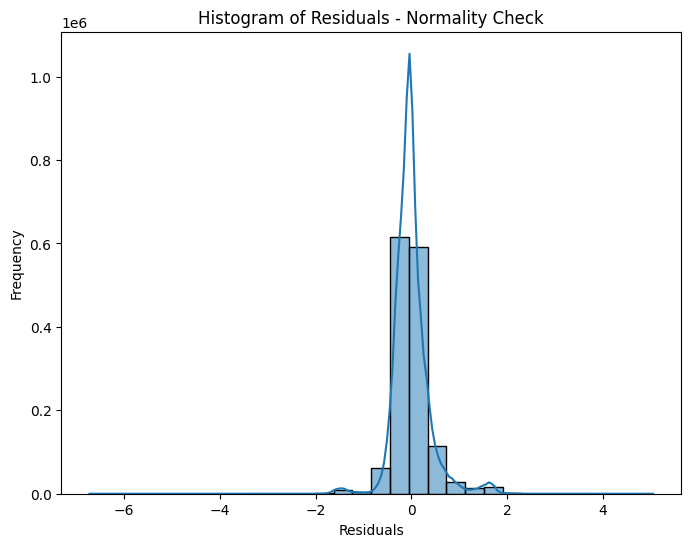

In [67]:
# Checking regression assumptions for the multiple regression model

# Get the residuals and fitted values
residuals = model.resid
fitted_vals = model.fittedvalues

# 1. Normality of residuals - Histogram
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, bins=30)
plt.title('Histogram of Residuals - Normality Check')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()

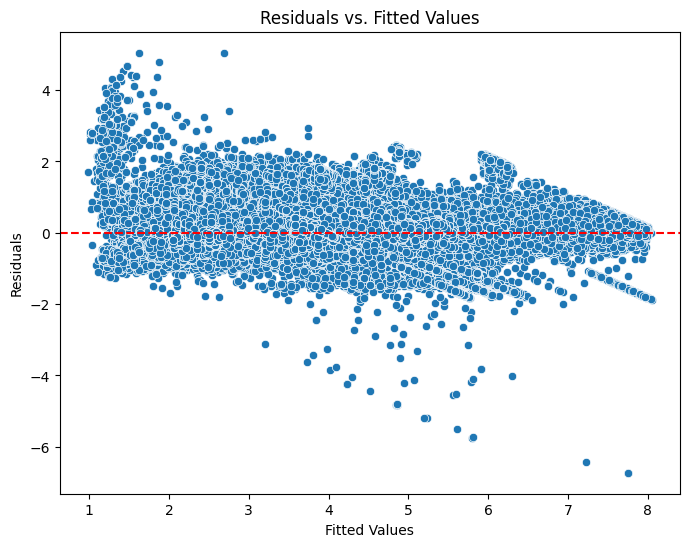

In [68]:
# 2. Homoscedasticity (constant variance)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=fitted_vals, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs. Fitted Values')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

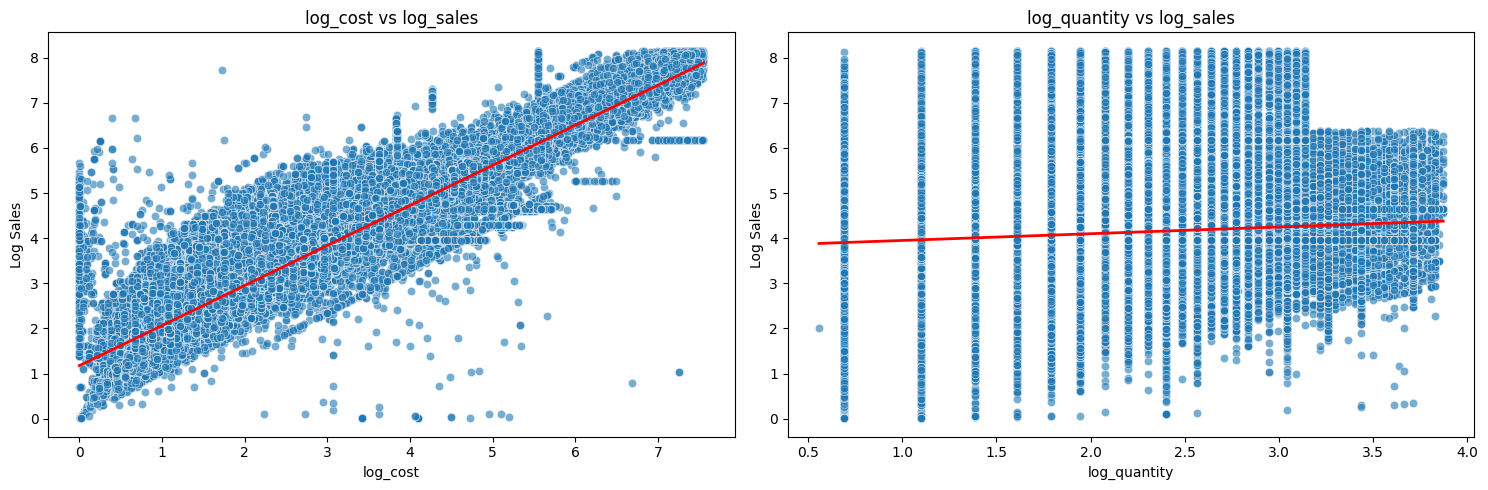

In [69]:
# Linearity check for numeric vars
numerical_vars = ['log_cost', 'log_quantity']

fig, axes = plt.subplots(1, len(numerical_vars), figsize=(15, 5))

for i, predictor in enumerate(numerical_vars):
    sns.scatterplot(data=df_encoded, x=predictor, y='log_sales', ax=axes[i], alpha=0.6)
    # Add regression line
    sns.regplot(data=df_encoded, x=predictor, y='log_sales', ax=axes[i],
                scatter=False, color='red', line_kws={'linewidth': 2})
    axes[i].set_title(f'{predictor} vs log_sales')
    axes[i].set_xlabel(predictor)
    axes[i].set_ylabel('Log Sales')

plt.tight_layout()
plt.show()

**Summary of explanation for regression assumptions** <br>
Normality: The residuals are acceptably normally distributed, centered at zero with low variance. <br>
Homoscedasticity: The assumption of constant variance is met. The residuals are densely packed around zero, indicating consistent error variance. <br>
Linearity: The continuous predictors show a strong linear relationship with the log-transformed outcome variable. The discrete, vertical patterns observed for the log_quantity variable may be a reflection of real-world business behavior, where customers order in specific quantity tiers.

## 4.4. Insights and Recommendations
(From regression results)

- Cost is the dominant predictor of sales, suggesting that higher-cost products tend to generate higher sales revenues. This may be due to product mix which means that higher costs are associated with more premium products or larger volume transactions. <br> *Recommendation:* Continue to expand higher-value product lines but also make sure that they are profitable. High sales does not necessarily mean high margins. It is better to review the profit margin on these products considering that they also cost highly.
  
-  Although there is a positive relationship between quantity and sales, a 1% increase in quantity is only associated with 0.066% increase in sales, which may indicate pricing strategies like bulk discounts. <br>
*Recommendation:* Review pricing and discount policies for bulk sales to ensure volume growth translates to sufficient revenue and profit.

- Products: In terms of product classification (abc_class_code), the following perform better than reference group: J - Make to Order - component stock to support delivery offer, B - Mid Sellers, D - National Discountinued. This suggests that class A (top performers) do not solely dominate sales and that these categories have further growth potential. LED products also sells better. <br>
*Recommendation:* Consider increasing the promotions for make-to-order and mid-sellers. Also review product mix. There may be products that are actually high selling but are tagged differently and could be overlooked which makes it harder for the company to consider these products when it comes to pricing strategies, marketing promotions, etc. As for LED products, it is recommended to study market trends to understand how demand for this lighting technology evolves over time and in certain markets. This way, strategies tied to LED product mix and pricing can be reassessed depending on the emerging trends.

- When it comes to business area, surface lighting (SUR) emerges as sales driver. This may be due to several factors including the kind of incentives that drives the sales force in this business area or the demand for surface lighting itself. <br>
*Recommendation:* Understand the driving forces behind this high-performing area which could be benchmarked and replicated in others.

- As for technology group, SYLV, based on the t-test results, is one of the top-selling technology groups by quantity and has a premium unit price ($9.55 vs $3.90 for the second top seller). This shows strong demand for a premium product. However, the regression shows that relative to the reference technology group, SYLV sells about 8% fewer units, considering only internal product and business features (like price, product type, warehouse, order type, and ABC class). This does not contradict the t-test because while the t-test confirms premium pricing and top-level sales, the regression reveals that given its internal characteristics, SYLV’s sales are slightly lower than expected. <br>
*Recommendation:* SYLV is performing well, but there’s potential to sell even more. Take a closer look at the product and pricing: assess whether the price is optimal, see if the features align with customer needs, and compare against competitors. Adjusting pricing, running targeted promotions, or improving product presentation could help SYLV reach more customers while maintaining its premium image.n.